# Allen MERFISH Multi-Slice Registration v2

This notebook is the starting scaffold for the slice-registration task using the Allen Brain Cell Atlas MERFISH whole-brain dataset.

Scope of `v2`:
- load two neighboring brain sections from the same donor using `abc_atlas_access`
- extract per-section expression and spatial coordinates
- normalize each section into its own `[0, 1] x [0, 1]` frame
- prepare tensors and a first affine-registration objective against learned continuous fields

This notebook does **not** yet assume a joint multi-slice splat model. The intended first experiment is:
1. train or load one field per section independently
2. freeze both fields
3. optimize an affine transform from section B into section A
4. evaluate pre/post alignment


This version extends the affine baseline with a smooth non-affine warp initialized from the affine result.


In [1]:
from pathlib import Path
import os
import sys
import random

import anndata
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np
import pandas as pd
from scipy.ndimage import distance_transform_edt
import torch
import torch.nn as nn
from dotenv import load_dotenv

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / "pyproject.toml").exists()
        and (PROJECT_ROOT / "spatsplat").is_dir()
        and (PROJECT_ROOT / "paper").is_dir()
    ):
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise RuntimeError("Could not find the spatsplat project root")

load_dotenv(PROJECT_ROOT / ".env")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from spatsplat import AmplitudeSplatField, SplatConfig, capture_initial_splat_state, composition_cosine_loss, compute_splat_weights, create_amplitude_splat_optimizer, evaluate_count_model, farthest_point_sample_indices, log_total_count_loss, mae_count_loss, sample_tissue_support, GeneProfileAutoencoder, evaluate_profile_autoencoder, train_profile_autoencoder
from spatsplat.baselines import CountMLP, KNNCountRegressor, MeanProfileBaseline

try:
    from abc_atlas_access.abc_atlas_cache.abc_project_cache import AbcProjectCache
except ImportError as exc:
    raise ImportError(
        'abc_atlas_access is required for this notebook. Install it first, then rerun this cell.'
    ) from exc


from PIL import Image

FIGURE_EXPORT_DIR = PROJECT_ROOT / 'figures' / 'allen_merfish_multislice_registration_v2'
FIGURE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def _slugify_figure_name(text: str) -> str:
    text = (text or '').strip().lower()
    text = ''.join(ch if ch.isalnum() else '_' for ch in text)
    while '__' in text:
        text = text.replace('__', '_')
    return text.strip('_') or 'figure'


def export_figure_axes(fig, fallback_prefix: str = "figure", dpi: int = 300, canvas_px: int = 2200):
    from PIL import Image

    titled_axes = []
    for ax in fig.axes:
        title = ax.get_title().strip() if hasattr(ax, "get_title") else ""
        if title:
            titled_axes.append((ax, title))
    if not titled_axes:
        return []

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width, height = fig.canvas.get_width_height()
    buf = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8).reshape(height, width, 4)
    all_bboxes = {ax: ax.get_tightbbox(renderer) for ax in fig.axes}
    saved_paths = []

    def _merge_with_adjacent_colorbars(main_ax, main_bbox):
        merged = main_bbox
        main_w = max(float(main_bbox.width), 1.0)
        main_h = max(float(main_bbox.height), 1.0)
        for other_ax in fig.axes:
            if other_ax is main_ax:
                continue
            other_bbox = all_bboxes.get(other_ax)
            if other_bbox is None:
                continue
            other_title = other_ax.get_title().strip() if hasattr(other_ax, "get_title") else ""
            if other_title:
                continue

            horiz_gap = min(abs(other_bbox.x1 - merged.x0), abs(other_bbox.x0 - merged.x1))
            vert_gap = min(abs(other_bbox.y1 - merged.y0), abs(other_bbox.y0 - merged.y1))
            y_overlap = max(0.0, min(merged.y1, other_bbox.y1) - max(merged.y0, other_bbox.y0))
            x_overlap = max(0.0, min(merged.x1, other_bbox.x1) - max(merged.x0, other_bbox.x0))

            is_vertical_bar = (
                other_bbox.width < 0.22 * main_w
                and y_overlap > 0.55 * min(main_h, float(other_bbox.height))
                and horiz_gap < 0.08 * main_w
                and other_bbox.x0 >= merged.x1
            )
            is_horizontal_bar = (
                other_bbox.height < 0.22 * main_h
                and x_overlap > 0.55 * min(main_w, float(other_bbox.width))
                and vert_gap < 0.08 * main_h
                and other_bbox.y1 <= merged.y0
            )
            if is_vertical_bar or is_horizontal_bar:
                merged = merged.union([merged, other_bbox])
        return merged

    for idx, (ax, title) in enumerate(titled_axes, start=1):
        base = _slugify_figure_name(f"{fallback_prefix}_{title}")
        if not base:
            base = _slugify_figure_name(f"{fallback_prefix}_{idx}")
        out_path = FIGURE_EXPORT_DIR / f"{base}.png"

        bbox = _merge_with_adjacent_colorbars(ax, all_bboxes[ax]).expanded(1.03, 1.08)
        x0 = max(0, int(np.floor(bbox.x0)))
        y0 = max(0, int(np.floor(bbox.y0)))
        x1 = min(width, int(np.ceil(bbox.x1)))
        y1 = min(height, int(np.ceil(bbox.y1)))
        if x1 <= x0 or y1 <= y0:
            continue

        crop = buf[height - y1:height - y0, x0:x1].copy()
        crop_img = Image.fromarray(crop)
        side = max(crop_img.width, crop_img.height)
        square = Image.new("RGBA", (side, side), (255, 255, 255, 255))
        offset = ((side - crop_img.width) // 2, (side - crop_img.height) // 2)
        square.paste(crop_img, offset)
        if side != canvas_px:
            square = square.resize((canvas_px, canvas_px), Image.Resampling.LANCZOS)
        square.save(out_path)
        saved_paths.append(str(out_path))
    return saved_paths


In [2]:
data_dir = os.getenv('SPATSPLAT_DATA_DIR')
if not data_dir:
    raise RuntimeError('SPATSPLAT_DATA_DIR is not set; copy .env.example to .env and edit it for your machine.')

download_base = Path(os.getenv('SPATSPLAT_ABC_ATLAS_DIR', str(Path(data_dir) / 'raw' / 'abc_atlas')))
dataset_directory = 'MERFISH-C57BL6J-638850'
expression_file = 'C57BL6J-638850/log2'

section_label_a = None
section_label_b = None
auto_section_index = None
auto_section_gap = 1
section_max_cells = None
random_seed = 1023
plot_point_size = 0.35
registration_query_count = 4096
device = 'cuda' if torch.cuda.is_available() else 'cpu'
baseline_val_fraction = 0.1
baseline_test_fraction = 0.1
baseline_mlp_hidden_dim = 128
baseline_mlp_epochs = 100
baseline_mlp_batch_size = 4096
baseline_mlp_lr = 1e-3
baseline_knn_k = 32
registration_marker_gene = 'Slc17a7'
registration_epochs = 500
registration_lr = 1e-2
registration_log_every = 50
registration_rigid_reg_weight = 1e-2
nonaffine_grid_size = 8
nonaffine_epochs = 400
nonaffine_lr = 5e-3
nonaffine_smoothness_weight = 1e-2
nonaffine_splat_match_weight = 1.0
nonaffine_min_valid_fraction = 0.25

splat_cfg = SplatConfig(num_splats=512, latent_dim=32, hidden_dim=128, init_log_scale=-4.5, kernel_sharpness=0.5)
init_log_amplitude = 6.0
shared_ae_epochs = 150
shared_ae_batch_size = 512
shared_ae_lr = 1e-3
section_splat_epochs = 150
section_splat_batch_size = 2048
section_splat_means_lr = 5e-3
section_splat_log_scales_lr = 1e-3
section_splat_rotation_lr = 1e-3
section_splat_opacity_lr = 1e-3
section_splat_latents_lr = 1e-3
section_splat_decoder_lr = 1e-3
section_splat_amplitude_lr = 1e-3
section_composition_loss_weight = 1.0
section_total_count_loss_weight = 0.2
section_mae_refine_weight = 1.0
section_mae_refine_fraction = 0.25
seed_neighbor_k = 16
section_mask_grid_size = 128
section_cell_mask_min_radius = 1.5
section_off_tissue_batch_size = 2048
section_off_tissue_weight = 0.01
section_center_support_weight = 0.001
display_sig_digits = 4


def format_scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if np.isnan(value) or np.isinf(value):
            return value
        return float(f'{value:.{display_sig_digits}g}')
    return value


def format_for_display(obj):
    if isinstance(obj, dict):
        return {k: format_for_display(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [format_for_display(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(format_for_display(v) for v in obj)
    return format_scalar(obj)

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def section_order_key(section_label: str) -> tuple[str, int]:
    label = str(section_label)
    donor_prefix, suffix = label.rsplit('.', 1)
    return donor_prefix, int(suffix)


set_seed(random_seed)
print(f'download_base = {download_base}')
print(f'dataset_directory = {dataset_directory}')
print(f'device = {device}')


download_base = /data/spatsplat/data/raw/abc_atlas
dataset_directory = MERFISH-C57BL6J-638850
device = cuda


In [3]:
abc_cache = AbcProjectCache.from_cache_dir(download_base)

cell_metadata = abc_cache.get_metadata_dataframe(
    directory=dataset_directory,
    file_name='cell_metadata',
    dtype={'cell_label': str},
).set_index('cell_label')

section_labels = sorted(cell_metadata['brain_section_label'].unique(), key=section_order_key)
donor_labels = sorted(cell_metadata['donor_label'].unique())

print('donor_labels:', donor_labels)
print('num_sections:', len(section_labels))
print('first_sections:', section_labels[:5])
print('last_sections:', section_labels[-5:])


cell_metadata.csv: 100%|██████████| 710M/710M [00:21<00:00, 32.8MMB/s]    


donor_labels: ['C57BL6J-638850']
num_sections: 59
first_sections: ['C57BL6J-638850.01', 'C57BL6J-638850.02', 'C57BL6J-638850.03', 'C57BL6J-638850.04', 'C57BL6J-638850.05']
last_sections: ['C57BL6J-638850.64', 'C57BL6J-638850.66', 'C57BL6J-638850.67', 'C57BL6J-638850.68', 'C57BL6J-638850.69']


In [4]:
if section_label_a is None or section_label_b is None:
    if auto_section_index is None:
        auto_section_index = max(0, min(len(section_labels) // 2, len(section_labels) - 1 - auto_section_gap))
    section_label_a = section_labels[auto_section_index]
    section_label_b = section_labels[auto_section_index + auto_section_gap]

assert section_label_a in section_labels, f'Unknown section_label_a: {section_label_a}'
assert section_label_b in section_labels, f'Unknown section_label_b: {section_label_b}'

section_meta_a = cell_metadata[cell_metadata['brain_section_label'] == section_label_a].copy()
section_meta_b = cell_metadata[cell_metadata['brain_section_label'] == section_label_b].copy()

print('section_label_a:', section_label_a, '| cells:', len(section_meta_a), '| median z:', format_scalar(float(section_meta_a['z'].median())))
print('section_label_b:', section_label_b, '| cells:', len(section_meta_b), '| median z:', format_scalar(float(section_meta_b['z'].median())))


section_label_a: C57BL6J-638850.36 | cells: 115779 | median z: 6.4
section_label_b: C57BL6J-638850.37 | cells: 90145 | median z: 6.6


In [5]:
h5ad_path = abc_cache.get_file_path(directory=dataset_directory, file_name=expression_file)
adata_backed = anndata.read_h5ad(h5ad_path, backed='r')
print(adata_backed)


def _to_dense(x):
    return x.toarray() if hasattr(x, 'toarray') else np.asarray(x)


def load_section_adata(backed_adata, metadata: pd.DataFrame, section_label: str, max_cells: int | None = None):
    section_meta = metadata[metadata['brain_section_label'] == section_label].copy()
    section_cell_ids = section_meta.index.astype(str)

    if max_cells is not None and len(section_cell_ids) > max_cells:
        keep_ids = np.random.choice(section_cell_ids.to_numpy(), size=max_cells, replace=False)
        keep_ids = pd.Index(sorted(keep_ids))
        section_meta = section_meta.loc[keep_ids].copy()
        section_cell_ids = section_meta.index.astype(str)

    section_adata = backed_adata[section_cell_ids].to_memory()
    section_adata.obs = section_meta.loc[section_adata.obs_names].copy()
    return section_adata


adata_a = load_section_adata(adata_backed, cell_metadata, section_label_a, max_cells=section_max_cells)
adata_b = load_section_adata(adata_backed, cell_metadata, section_label_b, max_cells=section_max_cells)

print('section A shape:', adata_a.shape)
print('section B shape:', adata_b.shape)


C57BL6J-638850-log2.h5ad: 100%|██████████| 7.63G/7.63G [03:46<00:00, 33.7MMB/s]    


AnnData object with n_obs × n_vars = 4334174 × 550 backed at '/data/spatsplat/data/raw/abc_atlas/expression_matrices/MERFISH-C57BL6J-638850/20230830/C57BL6J-638850-log2.h5ad'
    obs: 'brain_section_label'
    var: 'gene_symbol', 'transcript_identifier'
    uns: 'accessed_on', 'src'
section A shape: (115779, 550)
section B shape: (90145, 550)


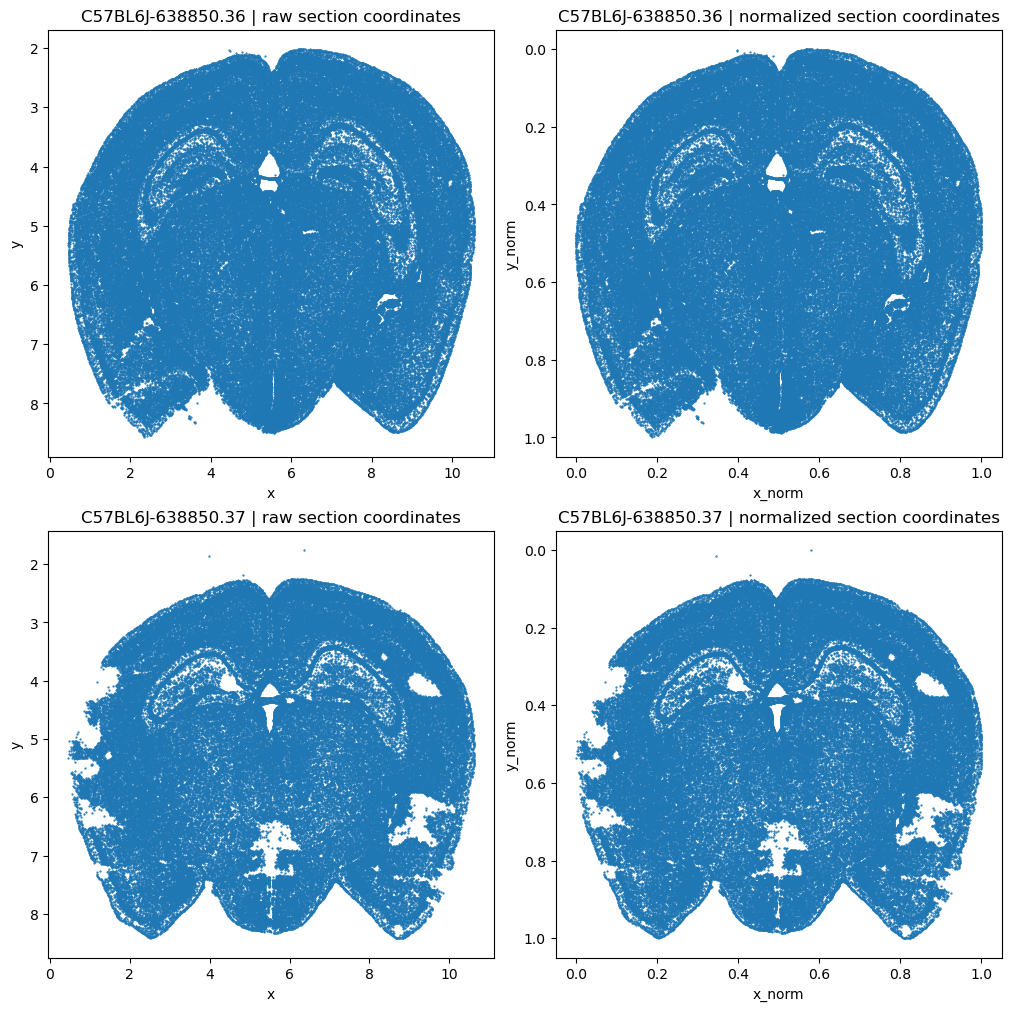

In [6]:
def normalize_section_xy(obs: pd.DataFrame, x_col: str = 'x', y_col: str = 'y'):
    xy = obs[[x_col, y_col]].to_numpy(dtype=np.float32)
    xy_min = xy.min(axis=0)
    xy_max = xy.max(axis=0)
    xy_range = np.clip(xy_max - xy_min, 1e-6, None)
    xy_norm = (xy - xy_min) / xy_range
    return xy, xy_norm, xy_min, xy_max


for adata in [adata_a, adata_b]:
    xy_raw, xy_norm, xy_min, xy_max = normalize_section_xy(adata.obs)
    adata.obsm['xy_raw'] = xy_raw
    adata.obsm['xy_norm'] = xy_norm
    adata.uns['xy_min'] = xy_min
    adata.uns['xy_max'] = xy_max

fig, axes = plt.subplots(2, 2, figsize=(10, 10), constrained_layout=True)
for row, (label, adata) in enumerate([(section_label_a, adata_a), (section_label_b, adata_b)]):
    xy_raw = adata.obsm['xy_raw']
    xy_norm = adata.obsm['xy_norm']

    axes[row, 0].scatter(xy_raw[:, 0], xy_raw[:, 1], s=plot_point_size)
    axes[row, 0].set_title(f'{label} | raw section coordinates')
    axes[row, 0].set_xlabel('x')
    axes[row, 0].set_ylabel('y')
    axes[row, 0].invert_yaxis()

    axes[row, 1].scatter(xy_norm[:, 0], xy_norm[:, 1], s=plot_point_size)
    axes[row, 1].set_title(f'{label} | normalized section coordinates')
    axes[row, 1].set_xlabel('x_norm')
    axes[row, 1].set_ylabel('y_norm')
    axes[row, 1].invert_yaxis()

export_figure_axes(fig, fallback_prefix='section_coordinates')
plt.show()


In [7]:
def build_section_tissue_support(xy_norm: np.ndarray, grid_size: int = section_mask_grid_size, min_radius: float = section_cell_mask_min_radius):
    mask = np.zeros((grid_size, grid_size), dtype=np.uint8)
    x_idx = np.clip(np.rint(xy_norm[:, 0] * (grid_size - 1)).astype(int), 0, grid_size - 1)
    y_idx = np.clip(np.rint(xy_norm[:, 1] * (grid_size - 1)).astype(int), 0, grid_size - 1)
    mask[y_idx, x_idx] = 1
    dist = distance_transform_edt(1 - mask)
    support = (dist <= float(min_radius)).astype(np.float32)
    support_tensor = torch.tensor(support, dtype=torch.float32).view(1, 1, grid_size, grid_size)

    grid_lin = np.linspace(0.0, 1.0, grid_size, dtype=np.float32)
    xx, yy = np.meshgrid(grid_lin, grid_lin, indexing='xy')
    off_mask = support < 0.5
    off_points = np.stack([xx[off_mask], yy[off_mask]], axis=1) if np.any(off_mask) else np.empty((0, 2), dtype=np.float32)
    return support_tensor, torch.tensor(off_points, dtype=torch.float32)


def build_section_tensors(adata):
    counts = _to_dense(adata.X).astype(np.float32)
    total_counts = counts.sum(axis=1, keepdims=True)
    profiles = counts / np.clip(total_counts, 1e-6, None)
    xy_norm = adata.obsm['xy_norm'].astype(np.float32)
    tissue_mask_tensor, off_tissue_points = build_section_tissue_support(xy_norm)
    return {
        'counts': torch.tensor(counts, dtype=torch.float32),
        'total_counts': torch.tensor(total_counts, dtype=torch.float32),
        'profiles': torch.tensor(profiles, dtype=torch.float32),
        'xy_norm': torch.tensor(xy_norm, dtype=torch.float32),
        'xy_raw': torch.tensor(adata.obsm['xy_raw'], dtype=torch.float32),
        'gene_names': list(map(str, adata.var.get('gene_symbol', adata.var_names))),
        'tissue_mask_tensor': tissue_mask_tensor.to(device),
        'off_tissue_points': off_tissue_points.to(device),
    }


section_data_a = build_section_tensors(adata_a)
section_data_b = build_section_tensors(adata_b)

print(format_for_display({
    'section_a_cells': int(section_data_a['counts'].shape[0]),
    'section_b_cells': int(section_data_b['counts'].shape[0]),
    'num_genes': int(section_data_a['counts'].shape[1]),
    'median_total_count_a': float(section_data_a['total_counts'].median().item()),
    'median_total_count_b': float(section_data_b['total_counts'].median().item()),
    'off_tissue_points_a': int(section_data_a['off_tissue_points'].shape[0]),
    'off_tissue_points_b': int(section_data_b['off_tissue_points'].shape[0]),
}))


{'section_a_cells': 115779, 'section_b_cells': 90145, 'num_genes': 550, 'median_total_count_a': 262.1, 'median_total_count_b': 208.8, 'off_tissue_points_a': 2689, 'off_tissue_points_b': 3832}


In [8]:
def make_section_split_indices(n: int, val_fraction: float = baseline_val_fraction, test_fraction: float = baseline_test_fraction, seed: int = random_seed):
    rng = np.random.default_rng(seed)
    perm = rng.permutation(n)
    n_test = int(round(test_fraction * n))
    n_val = int(round(val_fraction * n))
    n_test = min(max(n_test, 1), max(1, n - 2))
    n_val = min(max(n_val, 1), max(1, n - n_test - 1))
    test_idx = perm[:n_test]
    val_idx = perm[n_test:n_test + n_val]
    train_idx = perm[n_test + n_val:]
    return {
        'train': torch.tensor(train_idx, dtype=torch.long),
        'val': torch.tensor(val_idx, dtype=torch.long),
        'test': torch.tensor(test_idx, dtype=torch.long),
    }


def train_section_mlp(section_xy: torch.Tensor, section_counts: torch.Tensor, split_idx: dict[str, torch.Tensor], *, hidden_dim: int = baseline_mlp_hidden_dim, epochs: int = baseline_mlp_epochs, batch_size: int = baseline_mlp_batch_size, lr: float = baseline_mlp_lr, seed: int = random_seed):
    set_seed(seed)
    model = CountMLP(input_dim=2, hidden_dim=hidden_dim, output_dim=section_counts.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    xy = section_xy.to(device)
    counts = section_counts.to(device)
    train_idx = split_idx['train'].to(device)
    val_idx = split_idx['val'].to(device)
    test_idx = split_idx['test'].to(device)

    history = {'train_loss': [], 'val_loss': [], 'val_mae': []}
    for epoch in range(epochs):
        model.train()
        perm = train_idx[torch.randperm(len(train_idx), device=device)]
        running_loss = 0.0
        seen = 0
        for start in range(0, len(perm), batch_size):
            idx = perm[start:start + batch_size]
            pred_log_rate = model(xy[idx])
            loss = mae_count_loss(pred_log_rate, counts[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            running_loss += loss.item() * len(idx)
            seen += len(idx)

        val_metrics = evaluate_count_model(model, xy, counts, val_idx, batch_size=batch_size, loss_fn=mae_count_loss)
        history['train_loss'].append(running_loss / max(seen, 1))
        history['val_loss'].append(val_metrics['loss'])
        history['val_mae'].append(val_metrics['mae'])

    train_metrics = evaluate_count_model(model, xy, counts, train_idx, batch_size=batch_size, loss_fn=mae_count_loss)
    val_metrics = evaluate_count_model(model, xy, counts, val_idx, batch_size=batch_size, loss_fn=mae_count_loss)
    test_metrics = evaluate_count_model(model, xy, counts, test_idx, batch_size=batch_size, loss_fn=mae_count_loss)

    return {
        'model': model,
        'history': history,
        'summary': {'train': train_metrics, 'val': val_metrics, 'test': test_metrics},
        'split_idx': {'train': train_idx.detach().cpu(), 'val': val_idx.detach().cpu(), 'test': test_idx.detach().cpu()},
    }


def build_section_knn(section_xy: torch.Tensor, section_counts: torch.Tensor, split_idx: dict[str, torch.Tensor], *, k: int = baseline_knn_k):
    train_idx = split_idx['train']
    model = KNNCountRegressor(section_xy[train_idx].to(device), section_counts[train_idx].to(device), k=k).to(device)
    summary = {
        'train': evaluate_count_model(model, section_xy.to(device), section_counts.to(device), train_idx.to(device), loss_fn=mae_count_loss),
        'val': evaluate_count_model(model, section_xy.to(device), section_counts.to(device), split_idx['val'].to(device), loss_fn=mae_count_loss),
        'test': evaluate_count_model(model, section_xy.to(device), section_counts.to(device), split_idx['test'].to(device), loss_fn=mae_count_loss),
    }
    return {'model': model, 'summary': summary, 'split_idx': split_idx}


def build_section_mean_baseline(section_xy: torch.Tensor, section_counts: torch.Tensor, split_idx: dict[str, torch.Tensor]):
    model = MeanProfileBaseline(section_counts[split_idx['train']].to(device)).to(device)
    summary = {
        'train': evaluate_count_model(model, section_xy.to(device), section_counts.to(device), split_idx['train'].to(device), loss_fn=mae_count_loss),
        'val': evaluate_count_model(model, section_xy.to(device), section_counts.to(device), split_idx['val'].to(device), loss_fn=mae_count_loss),
        'test': evaluate_count_model(model, section_xy.to(device), section_counts.to(device), split_idx['test'].to(device), loss_fn=mae_count_loss),
    }
    return {'model': model, 'summary': summary, 'split_idx': split_idx}


In [9]:
section_splits = {
    section_label_a: make_section_split_indices(section_data_a['xy_norm'].shape[0], seed=random_seed + 100),
    section_label_b: make_section_split_indices(section_data_b['xy_norm'].shape[0], seed=random_seed + 200),
}

for label, split_idx in section_splits.items():
    print(label, format_for_display({k: int(v.numel()) for k, v in split_idx.items()}))


C57BL6J-638850.36 {'train': 92623, 'val': 11578, 'test': 11578}
C57BL6J-638850.37 {'train': 72117, 'val': 9014, 'test': 9014}


In [10]:
mlp_result_a = train_section_mlp(section_data_a['xy_norm'], section_data_a['counts'], section_splits[section_label_a], seed=random_seed + 101)
mlp_result_b = train_section_mlp(section_data_b['xy_norm'], section_data_b['counts'], section_splits[section_label_b], seed=random_seed + 201)

mean_result_a = build_section_mean_baseline(section_data_a['xy_norm'], section_data_a['counts'], section_splits[section_label_a])
mean_result_b = build_section_mean_baseline(section_data_b['xy_norm'], section_data_b['counts'], section_splits[section_label_b])

knn_result_a = build_section_knn(section_data_a['xy_norm'], section_data_a['counts'], section_splits[section_label_a])
knn_result_b = build_section_knn(section_data_b['xy_norm'], section_data_b['counts'], section_splits[section_label_b])

baseline_field_results = {
    section_label_a: {'Mean baseline': mean_result_a, 'MLP-MAE': mlp_result_a, 'KNN': knn_result_a},
    section_label_b: {'Mean baseline': mean_result_b, 'MLP-MAE': mlp_result_b, 'KNN': knn_result_b},
}

baseline_summary = {
    section_label_a: {name: result['summary'] for name, result in baseline_field_results[section_label_a].items()},
    section_label_b: {name: result['summary'] for name, result in baseline_field_results[section_label_b].items()},
}

print('Baseline field summary')
print(format_for_display(baseline_summary))


Baseline field summary
{'C57BL6J-638850.36': {'Mean baseline': {'train': {'loss': 0.549, 'mae': 0.549, 'n': 92623}, 'val': {'loss': 0.5478, 'mae': 0.5478, 'n': 11578}, 'test': {'loss': 0.5484, 'mae': 0.5484, 'n': 11578}}, 'MLP-MAE': {'train': {'loss': 0.4239, 'mae': 0.4239, 'n': 92623}, 'val': {'loss': 0.4209, 'mae': 0.4209, 'n': 11578}, 'test': {'loss': 0.4228, 'mae': 0.4228, 'n': 11578}}, 'KNN': {'train': {'loss': 0.02391, 'mae': 0.02391, 'n': 92623}, 'val': {'loss': 0.416, 'mae': 0.416, 'n': 11578}, 'test': {'loss': 0.4165, 'mae': 0.4165, 'n': 11578}}}, 'C57BL6J-638850.37': {'Mean baseline': {'train': {'loss': 0.4706, 'mae': 0.4706, 'n': 72117}, 'val': {'loss': 0.472, 'mae': 0.472, 'n': 9014}, 'test': {'loss': 0.4695, 'mae': 0.4695, 'n': 9014}}, 'MLP-MAE': {'train': {'loss': 0.3537, 'mae': 0.3537, 'n': 72117}, 'val': {'loss': 0.356, 'mae': 0.356, 'n': 9014}, 'test': {'loss': 0.3527, 'mae': 0.3527, 'n': 9014}}, 'KNN': {'train': {'loss': 0.02181, 'mae': 0.02181, 'n': 72117}, 'val': {'

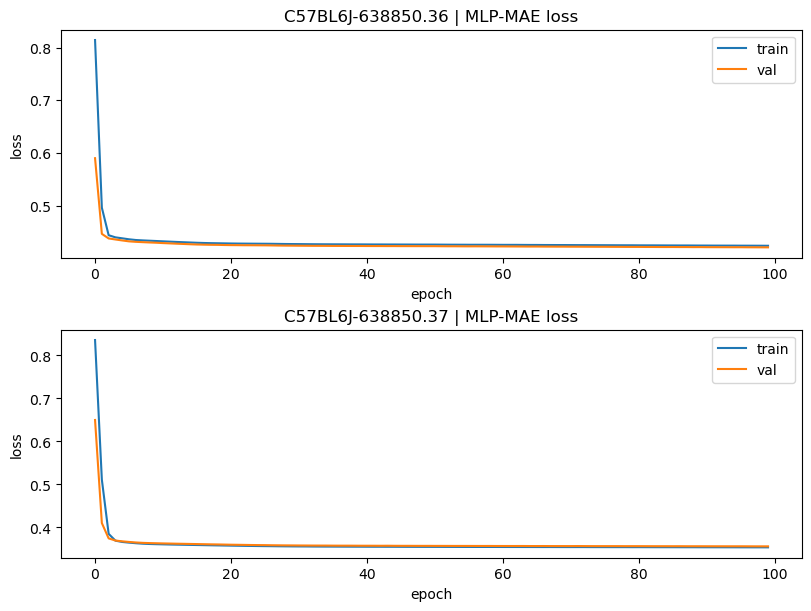

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), constrained_layout=True)
for row, (label, mlp_result) in enumerate([
    (section_label_a, mlp_result_a),
    (section_label_b, mlp_result_b),
]):
    axes[row].plot(mlp_result['history']['train_loss'], label='train')
    axes[row].plot(mlp_result['history']['val_loss'], label='val')
    axes[row].set_title(f'{label} | MLP-MAE loss')
    axes[row].set_xlabel('epoch')
    axes[row].set_ylabel('loss')
    axes[row].legend()

export_figure_axes(fig, fallback_prefix='mlp_training')
plt.show()


## Shared AE For Splat Seeding

Train one profile autoencoder on the union of both sections, then use that shared latent space to initialize one splat field per section.


In [12]:
combined_profiles = torch.cat([section_data_a['profiles'], section_data_b['profiles']], dim=0)
combined_counts = torch.cat([section_data_a['counts'], section_data_b['counts']], dim=0)
combined_split_idx = make_section_split_indices(combined_profiles.shape[0], seed=random_seed + 300)

set_seed(random_seed + 301)
shared_profile_autoencoder = GeneProfileAutoencoder(
    num_genes=section_data_a['counts'].shape[1],
    hidden_dim=splat_cfg.hidden_dim,
    latent_dim=splat_cfg.latent_dim,
).to(device)
shared_profile_autoencoder_opt = torch.optim.Adam(shared_profile_autoencoder.parameters(), lr=shared_ae_lr)

shared_ae_history = train_profile_autoencoder(
    shared_profile_autoencoder,
    combined_profiles,
    combined_split_idx['train'],
    combined_split_idx['val'],
    epochs=shared_ae_epochs,
    batch_size=shared_ae_batch_size,
    optimizer=shared_profile_autoencoder_opt,
    max_grad_norm=5.0,
)

shared_ae_summary = {
    'train': evaluate_profile_autoencoder(shared_profile_autoencoder, combined_profiles, combined_split_idx['train'], batch_size=shared_ae_batch_size),
    'val': evaluate_profile_autoencoder(shared_profile_autoencoder, combined_profiles, combined_split_idx['val'], batch_size=shared_ae_batch_size),
    'test': evaluate_profile_autoencoder(shared_profile_autoencoder, combined_profiles, combined_split_idx['test'], batch_size=shared_ae_batch_size),
}
print('Shared AE summary')
print(format_for_display(shared_ae_summary))


Shared AE summary
{'train': {'loss': 5.301, 'mae': 0.001208, 'cosine': 0.8823, 'n': 164740}, 'val': {'loss': 5.303, 'mae': 0.001213, 'cosine': 0.8815, 'n': 20592}, 'test': {'loss': 5.303, 'mae': 0.001213, 'cosine': 0.8812, 'n': 20592}}


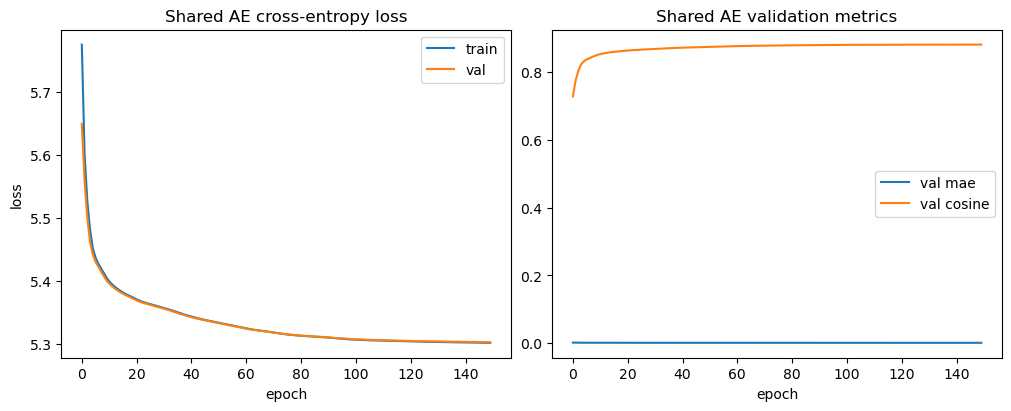

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].plot(shared_ae_history['train_loss'], label='train')
axes[0].plot(shared_ae_history['val_loss'], label='val')
axes[0].set_title('Shared AE cross-entropy loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()

axes[1].plot(shared_ae_history['val_mae'], label='val mae')
axes[1].plot(shared_ae_history['val_cosine'], label='val cosine')
axes[1].set_title('Shared AE validation metrics')
axes[1].set_xlabel('epoch')
axes[1].legend()
export_figure_axes(fig, fallback_prefix='shared_ae_training')
plt.show()


## Per-Section Splat Fields

Use the shared AE to seed one splat field per section, then train each section independently with a center-readout coarse objective.


In [14]:
def init_section_splat_model(section_xy: torch.Tensor, section_profiles: torch.Tensor, section_total_counts: torch.Tensor):
    with torch.no_grad():
        seed_idx = farthest_point_sample_indices(section_xy.to(device), splat_cfg.num_splats)
        seed_xy = section_xy.to(device)[seed_idx]
        pairwise_dist = torch.cdist(seed_xy, section_xy.to(device))
        neighbor_k = min(seed_neighbor_k, section_xy.shape[0])
        _, neighbor_idx = torch.topk(pairwise_dist, k=neighbor_k, largest=False, dim=1)

        neighbor_profiles = section_profiles.to(device)[neighbor_idx]
        neighbor_totals = section_total_counts.to(device)[neighbor_idx]
        avg_profiles = neighbor_profiles.mean(dim=1)
        avg_profiles = avg_profiles / avg_profiles.sum(dim=1, keepdim=True).clamp_min(1e-8)
        avg_totals = neighbor_totals.mean(dim=1)
        encoded_seed_latents = shared_profile_autoencoder.encoder(avg_profiles)

    model = AmplitudeSplatField(
        num_splats=splat_cfg.num_splats,
        latent_dim=splat_cfg.latent_dim,
        hidden_dim=splat_cfg.hidden_dim,
        num_genes=section_profiles.shape[1],
        init_log_scale=splat_cfg.init_log_scale,
        kernel_sharpness=splat_cfg.kernel_sharpness,
        init_log_amplitude=init_log_amplitude,
    ).to(device)

    with torch.no_grad():
        model.means.copy_(seed_xy)
        model.latents.copy_(encoded_seed_latents)
        model.log_amplitudes.copy_(avg_totals.clamp_min(1.0).log())
        model.log_scales.fill_(splat_cfg.init_log_scale)
        model.rotation.zero_()
        model.opacity_logits.zero_()
        model.decoder.load_state_dict(shared_profile_autoencoder.decoder.state_dict())

    return model


def clone_splat_model(model):
    cloned = AmplitudeSplatField(
        num_splats=model.num_splats,
        latent_dim=model.latent_dim,
        hidden_dim=model.hidden_dim,
        num_genes=model.num_genes,
        init_log_scale=model.init_log_scale,
        kernel_sharpness=model.kernel_sharpness,
        init_log_amplitude=float(model.log_amplitudes.detach().mean().item()),
    ).to(model.means.device)
    cloned.load_state_dict({k: v.detach().clone() for k, v in model.state_dict().items()})
    cloned.eval()
    return cloned


def evaluate_section_splat_model(model, section_xy: torch.Tensor, section_counts: torch.Tensor, split_idx: torch.Tensor, batch_size: int = 2048):
    was_training = model.training
    model.eval()
    total_loss = 0.0
    total_mae = 0.0
    total_seen = 0
    with torch.no_grad():
        for start in range(0, len(split_idx), batch_size):
            idx = split_idx[start:start + batch_size].to(device)
            pred_log_rate = model(section_xy.to(device)[idx])
            loss = mae_count_loss(pred_log_rate, section_counts.to(device)[idx])
            pred_counts = torch.exp(pred_log_rate)
            mae = (pred_counts - section_counts.to(device)[idx]).abs().mean()
            total_loss += loss.item() * len(idx)
            total_mae += mae.item() * len(idx)
            total_seen += len(idx)
    if was_training:
        model.train()
    return {'loss': total_loss / total_seen, 'mae': total_mae / total_seen, 'n': total_seen}


def train_section_splat_model(section_xy: torch.Tensor, section_counts: torch.Tensor, split_idx: dict[str, torch.Tensor], initial_model, *, label: str, seed: int, off_tissue_points: torch.Tensor, tissue_mask_tensor: torch.Tensor):
    set_seed(seed)
    model = clone_splat_model(initial_model)
    optimizer = create_amplitude_splat_optimizer(
        model,
        means_lr=section_splat_means_lr,
        log_scales_lr=section_splat_log_scales_lr,
        rotation_lr=section_splat_rotation_lr,
        opacity_lr=section_splat_opacity_lr,
        latents_lr=section_splat_latents_lr,
        decoder_lr=section_splat_decoder_lr,
        amplitude_lr=section_splat_amplitude_lr,
    )
    history = {'train_joint_loss': [], 'train_composition_loss': [], 'train_total_count_loss': [], 'train_cell_loss': [], 'train_off_tissue_loss': [], 'train_center_support_loss': [], 'val_loss': [], 'val_mae': [], 'val_phase': []}
    train_idx = split_idx['train'].to(device)
    val_idx = split_idx['val']
    xy = section_xy.to(device)
    counts = section_counts.to(device)
    mae_refine_start_epoch = max(0, int(round((1.0 - section_mae_refine_fraction) * section_splat_epochs)))

    for epoch in range(section_splat_epochs):
        model.train()
        mae_refine_active = epoch >= mae_refine_start_epoch
        perm = train_idx[torch.randperm(len(train_idx), device=device)]
        off_perm = torch.randperm(len(off_tissue_points), device=device) if len(off_tissue_points) > 0 else None
        running = {'joint_loss': 0.0, 'cell_loss': 0.0, 'composition_loss': 0.0, 'total_count_loss': 0.0, 'off_tissue_loss': 0.0, 'center_support_loss': 0.0}
        steps = 0
        for step, start in enumerate(range(0, len(perm), section_splat_batch_size)):
            idx = perm[start:start + section_splat_batch_size]
            pred_log_rate = model(xy[idx])
            cell_loss = mae_count_loss(pred_log_rate, counts[idx]) if mae_refine_active else pred_log_rate.new_tensor(0.0)
            composition_loss = composition_cosine_loss(torch.exp(pred_log_rate), counts[idx])
            total_count_loss = log_total_count_loss(pred_log_rate, counts[idx])
            if off_perm is not None and len(off_tissue_points) > 0:
                off_start = (step * section_off_tissue_batch_size) % len(off_perm)
                off_idx = off_perm[off_start:off_start + section_off_tissue_batch_size]
                if len(off_idx) == 0:
                    off_idx = off_perm[:section_off_tissue_batch_size]
                off_tissue_loss = model.total_intensity(off_tissue_points[off_idx]).mean()
            else:
                off_tissue_loss = pred_log_rate.new_tensor(0.0)
            center_support_loss = (1.0 - sample_tissue_support(model.means, tissue_mask_tensor)).mean()
            loss = section_mae_refine_weight * cell_loss + section_composition_loss_weight * composition_loss + section_total_count_loss_weight * total_count_loss + section_off_tissue_weight * off_tissue_loss + section_center_support_weight * center_support_loss
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            with torch.no_grad():
                model.means.clamp_(0.0, 1.0)
                model.log_scales.clamp_(-8.0, -2.0)
            running['joint_loss'] += loss.item()
            running['cell_loss'] += cell_loss.item()
            running['composition_loss'] += composition_loss.item()
            running['total_count_loss'] += total_count_loss.item()
            running['off_tissue_loss'] += off_tissue_loss.item()
            running['center_support_loss'] += center_support_loss.item()
            steps += 1

        train_metrics = {k: v / max(steps, 1) for k, v in running.items()}
        val_metrics = evaluate_section_splat_model(model, section_xy, section_counts, val_idx)
        history['train_joint_loss'].append(train_metrics['joint_loss'])
        history['train_composition_loss'].append(train_metrics['composition_loss'])
        history['train_total_count_loss'].append(train_metrics['total_count_loss'])
        history['train_cell_loss'].append(train_metrics['cell_loss'])
        history['train_off_tissue_loss'].append(train_metrics['off_tissue_loss'])
        history['train_center_support_loss'].append(train_metrics['center_support_loss'])
        history['val_loss'].append(val_metrics['loss'])
        history['val_mae'].append(val_metrics['mae'])
        history['val_phase'].append('mae_refine' if mae_refine_active else 'composition')

        if epoch == 0 or (epoch + 1) % 25 == 0 or epoch == section_splat_epochs - 1:
            print(f'{label} | epoch {epoch}:', format_for_display({'train': train_metrics, 'val': val_metrics, 'phase': history['val_phase'][-1]}))

    summary = {
        'train': evaluate_section_splat_model(model, section_xy, section_counts, split_idx['train']),
        'val': evaluate_section_splat_model(model, section_xy, section_counts, split_idx['val']),
        'test': evaluate_section_splat_model(model, section_xy, section_counts, split_idx['test']),
    }
    return {'model': model, 'history': history, 'summary': summary, 'initial_state': capture_initial_splat_state(model)}


In [15]:
section_a_init_splat = init_section_splat_model(section_data_a['xy_norm'], section_data_a['profiles'], section_data_a['total_counts'])
section_b_init_splat = init_section_splat_model(section_data_b['xy_norm'], section_data_b['profiles'], section_data_b['total_counts'])

section_a_splat_result = train_section_splat_model(
    section_data_a['xy_norm'], section_data_a['counts'], section_splits[section_label_a], section_a_init_splat,
    label=f'{section_label_a} | AE-neighbor splat', seed=random_seed + 401,
    off_tissue_points=section_data_a['off_tissue_points'], tissue_mask_tensor=section_data_a['tissue_mask_tensor'],
)
section_b_splat_result = train_section_splat_model(
    section_data_b['xy_norm'], section_data_b['counts'], section_splits[section_label_b], section_b_init_splat,
    label=f'{section_label_b} | AE-neighbor splat', seed=random_seed + 501,
    off_tissue_points=section_data_b['off_tissue_points'], tissue_mask_tensor=section_data_b['tissue_mask_tensor'],
)

splat_baseline_summary = {
    section_label_a: {'AE-neighbor splat': section_a_splat_result['summary']},
    section_label_b: {'AE-neighbor splat': section_b_splat_result['summary']},
}
print('Splat field summary')
print(format_for_display(splat_baseline_summary))


C57BL6J-638850.36 | AE-neighbor splat | epoch 0: {'train': {'joint_loss': 0.4557, 'cell_loss': 0.0, 'composition_loss': 0.2588, 'total_count_loss': 0.3118, 'off_tissue_loss': 13.45, 'center_support_loss': 0.002767}, 'val': {'loss': 0.4555, 'mae': 0.4555, 'n': 11578}, 'phase': 'composition'}
C57BL6J-638850.36 | AE-neighbor splat | epoch 24: {'train': {'joint_loss': 0.2972, 'cell_loss': 0.0, 'composition_loss': 0.2367, 'total_count_loss': 0.2865, 'off_tissue_loss': 0.3177, 'center_support_loss': 0.001914}, 'val': {'loss': 0.4431, 'mae': 0.4431, 'n': 11578}, 'phase': 'composition'}
C57BL6J-638850.36 | AE-neighbor splat | epoch 49: {'train': {'joint_loss': 0.2911, 'cell_loss': 0.0, 'composition_loss': 0.2336, 'total_count_loss': 0.2813, 'off_tissue_loss': 0.1248, 'center_support_loss': 0.001892}, 'val': {'loss': 0.4396, 'mae': 0.4396, 'n': 11578}, 'phase': 'composition'}
C57BL6J-638850.36 | AE-neighbor splat | epoch 74: {'train': {'joint_loss': 0.2894, 'cell_loss': 0.0, 'composition_loss':

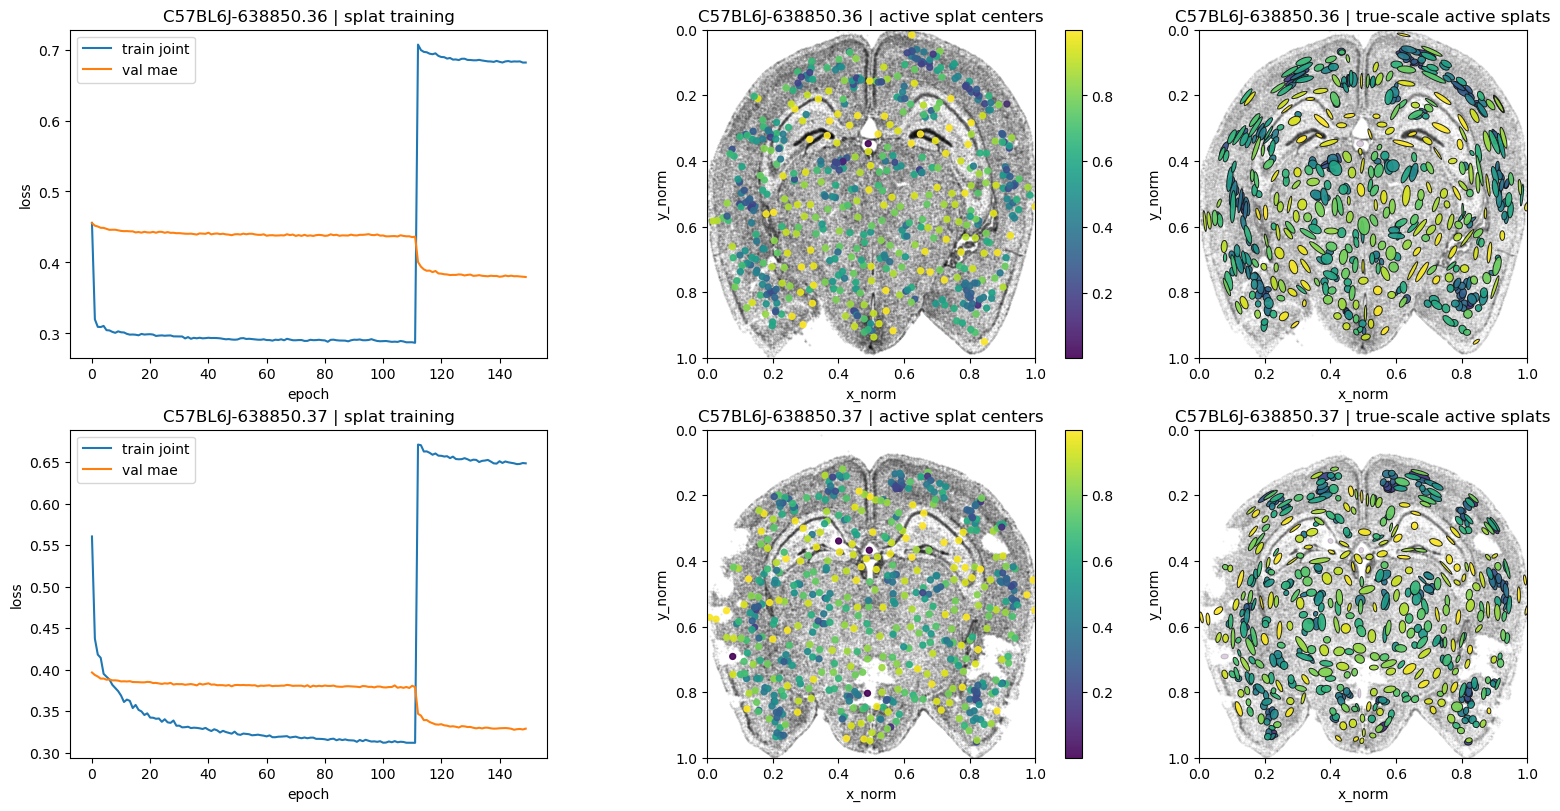

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
for row, (label, result, section_xy) in enumerate([
    (section_label_a, section_a_splat_result, section_data_a['xy_norm']),
    (section_label_b, section_b_splat_result, section_data_b['xy_norm']),
]):
    model = result['model']
    axes[row, 0].plot(result['history']['train_joint_loss'], label='train joint')
    axes[row, 0].plot(result['history']['val_loss'], label='val mae')
    axes[row, 0].set_title(f'{label} | splat training')
    axes[row, 0].set_xlabel('epoch')
    axes[row, 0].set_ylabel('loss')
    axes[row, 0].legend()

    with torch.no_grad():
        section_weights = compute_splat_weights(model, section_xy.to(device))
        mean_usage = section_weights.mean(dim=0).detach().cpu().numpy()
        full_weights = section_weights.detach().cpu().numpy()
        means_np = model.means.detach().cpu().numpy()
        scales_xy_np = torch.exp(model.log_scales).detach().cpu().numpy()
        rotation_np = model.rotation.detach().cpu().numpy().reshape(-1)

    section_xy_np = section_xy.detach().cpu().numpy()
    active_idx = np.flatnonzero(mean_usage > 1e-4)
    overlap_usage = np.zeros(len(mean_usage), dtype=np.float64)
    for splat_idx in active_idx:
        dx = section_xy_np[:, 0] - means_np[splat_idx, 0]
        dy = section_xy_np[:, 1] - means_np[splat_idx, 1]
        theta = -float(rotation_np[splat_idx])
        c, s = np.cos(theta), np.sin(theta)
        x_rot = c * dx - s * dy
        y_rot = s * dx + c * dy
        sx = max(float(scales_xy_np[splat_idx, 0]), 1e-8)
        sy = max(float(scales_xy_np[splat_idx, 1]), 1e-8)
        inside_mask = (x_rot / sx) ** 2 + (y_rot / sy) ** 2 <= 1.0
        if inside_mask.any():
            overlap_usage[splat_idx] = float(full_weights[inside_mask, splat_idx].mean())
        else:
            overlap_usage[splat_idx] = float(mean_usage[splat_idx])

    axes[row, 1].scatter(section_xy_np[:, 0], section_xy_np[:, 1], s=0.2, alpha=0.1, color='black')
    if len(active_idx):
        sc = axes[row, 1].scatter(means_np[active_idx, 0], means_np[active_idx, 1], s=18.0, c=overlap_usage[active_idx], cmap='viridis', alpha=0.9)
        fig.colorbar(sc, ax=axes[row, 1], fraction=0.046, pad=0.04)
    axes[row, 1].set_title(f'{label} | active splat centers')
    axes[row, 1].set_xlabel('x_norm')
    axes[row, 1].set_ylabel('y_norm')
    axes[row, 1].invert_yaxis()

    axes[row, 2].scatter(section_xy_np[:, 0], section_xy_np[:, 1], s=0.2, alpha=0.06, color='black')
    draw_order = np.argsort(overlap_usage[active_idx]) if len(active_idx) else np.array([], dtype=np.int64)
    overlap_max = float(overlap_usage[active_idx].max()) if len(active_idx) else 1.0
    for local_pos in draw_order:
        splat_idx = active_idx[local_pos]
        ellipse = Ellipse(
            xy=means_np[splat_idx],
            width=2.0 * scales_xy_np[splat_idx, 0],
            height=2.0 * scales_xy_np[splat_idx, 1],
            angle=float(np.degrees(rotation_np[splat_idx])),
            facecolor=plt.cm.viridis(min(1.0, max(0.0, overlap_usage[splat_idx] / (overlap_max + 1e-8)))),
            edgecolor=(0.08, 0.08, 0.08, 0.95),
            linewidth=0.7,
            alpha=float(np.clip(0.18 + 12.0 * overlap_usage[splat_idx], 0.18, 0.92)),
        )
        axes[row, 2].add_patch(ellipse)
    axes[row, 2].set_title(f'{label} | true-scale active splats')
    axes[row, 2].set_xlabel('x_norm')
    axes[row, 2].set_ylabel('y_norm')
    axes[row, 2].invert_yaxis()

    for ax in axes[row, 1:]:
        ax.set_xlim(0, 1)
        ax.set_ylim(1, 0)
        ax.set_aspect('equal')

export_figure_axes(fig, fallback_prefix='splat_training_and_layout')
plt.show()


In [17]:
class Affine2D(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Parameter(torch.eye(2, dtype=torch.float32))
        self.translation = nn.Parameter(torch.zeros(2, dtype=torch.float32))

    def forward(self, xy: torch.Tensor) -> torch.Tensor:
        return xy @ self.linear.T + self.translation

    def inverse(self, xy: torch.Tensor) -> torch.Tensor:
        linear_inv = torch.linalg.inv(self.linear)
        return (xy - self.translation) @ linear_inv.T


def sample_registration_queries(xy: torch.Tensor, n: int = registration_query_count) -> torch.Tensor:
    n = min(n, xy.shape[0])
    idx = torch.randperm(xy.shape[0])[:n]
    return xy[idx]


def in_bounds_mask(xy: torch.Tensor) -> torch.Tensor:
    return ((xy[:, 0] >= 0.0) & (xy[:, 0] <= 1.0) & (xy[:, 1] >= 0.0) & (xy[:, 1] <= 1.0))


def registration_loss_from_models(model_a, model_b, query_xy_a: torch.Tensor, transform: Affine2D, *, min_valid_fraction: float = 0.25):
    query_xy_b = transform(query_xy_a)
    valid_mask = in_bounds_mask(query_xy_b)
    valid_fraction = valid_mask.float().mean()

    if valid_mask.sum() == 0:
        invalid_loss = query_xy_b.new_tensor(1e3)
        return invalid_loss, valid_fraction

    rate_a = torch.exp(model_a(query_xy_a[valid_mask]))
    rate_b = torch.exp(model_b(query_xy_b[valid_mask]))
    field_loss = composition_cosine_loss(rate_a, rate_b)

    if valid_fraction < min_valid_fraction:
        field_loss = field_loss + (min_valid_fraction - valid_fraction) * 10.0

    return field_loss, valid_fraction


def mapped_profile_cosine_summary(model_a, model_b, query_xy_a: torch.Tensor, map_xy_fn, top_gene_k: int = 10):
    with torch.no_grad():
        query_xy_a = query_xy_a.to(device)
        query_xy_b = map_xy_fn(query_xy_a)
        valid_mask = in_bounds_mask(query_xy_b)
        valid_fraction = float(valid_mask.float().mean().item())
        if valid_mask.sum() == 0:
            return {
                'valid_fraction': valid_fraction,
                'mean_profile_cosine': float('nan'),
                'median_profile_cosine': float('nan'),
                'fraction_profile_cosine_ge_0_9': float('nan'),
                'mean_topk_overlap': float('nan'),
                'median_topk_overlap': float('nan'),
            }, {'profile_cosine': np.empty(0, dtype=np.float64), 'topk_overlap': np.empty(0, dtype=np.float64)}

        rate_a = torch.exp(model_a(query_xy_a[valid_mask]))
        rate_b = torch.exp(model_b(query_xy_b[valid_mask]))
        rate_a_norm = rate_a / rate_a.norm(dim=1, keepdim=True).clamp_min(1e-8)
        rate_b_norm = rate_b / rate_b.norm(dim=1, keepdim=True).clamp_min(1e-8)
        profile_cosine = (rate_a_norm * rate_b_norm).sum(dim=1).detach().cpu().numpy()

        top_gene_k = min(top_gene_k, rate_a.shape[1])
        top_a = torch.topk(rate_a, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        top_b = torch.topk(rate_b, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        topk_overlap = np.array([
            len(set(top_a[i].tolist()) & set(top_b[i].tolist())) / float(top_gene_k)
            for i in range(top_a.shape[0])
        ], dtype=np.float64)

    return {
        'valid_fraction': valid_fraction,
        'mean_profile_cosine': float(np.mean(profile_cosine)),
        'median_profile_cosine': float(np.median(profile_cosine)),
        'fraction_profile_cosine_ge_0_9': float(np.mean(profile_cosine >= 0.9)),
        'mean_topk_overlap': float(np.mean(topk_overlap)),
        'median_topk_overlap': float(np.median(topk_overlap)),
    }, {'profile_cosine': profile_cosine, 'topk_overlap': topk_overlap}


def crossslice_field_to_data_summary(source_model, target_xy: torch.Tensor, target_counts: torch.Tensor, inverse_map_fn, top_gene_k: int = 10):
    with torch.no_grad():
        target_xy = target_xy.to(device)
        target_counts = target_counts.to(device)
        source_xy = inverse_map_fn(target_xy)
        valid_mask = in_bounds_mask(source_xy)
        valid_fraction = float(valid_mask.float().mean().item())
        if valid_mask.sum() == 0:
            empty = np.empty(0, dtype=np.float64)
            return {
                'valid_fraction': valid_fraction,
                'mae': float('nan'),
                'mean_profile_cosine': float('nan'),
                'median_profile_cosine': float('nan'),
                'mean_topk_overlap': float('nan'),
                'median_topk_overlap': float('nan'),
            }, {'mae_per_measurement': empty, 'profile_cosine': empty, 'topk_overlap': empty}

        pred_counts = torch.exp(source_model(source_xy[valid_mask]))
        true_counts = target_counts[valid_mask]
        mae_per_measurement = (pred_counts - true_counts).abs().mean(dim=1).detach().cpu().numpy()
        pred_norm = pred_counts / pred_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
        true_norm = true_counts / true_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
        profile_cosine = (pred_norm * true_norm).sum(dim=1).detach().cpu().numpy()

        top_gene_k = min(top_gene_k, pred_counts.shape[1])
        top_pred = torch.topk(pred_counts, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        top_true = torch.topk(true_counts, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        topk_overlap = np.array([
            len(set(top_pred[i].tolist()) & set(top_true[i].tolist())) / float(top_gene_k)
            for i in range(top_pred.shape[0])
        ], dtype=np.float64)

    return {
        'valid_fraction': valid_fraction,
        'mae': float(np.mean(mae_per_measurement)),
        'mean_profile_cosine': float(np.mean(profile_cosine)),
        'median_profile_cosine': float(np.median(profile_cosine)),
        'mean_topk_overlap': float(np.mean(topk_overlap)),
        'median_topk_overlap': float(np.median(topk_overlap)),
    }, {
        'mae_per_measurement': mae_per_measurement,
        'profile_cosine': profile_cosine,
        'topk_overlap': topk_overlap,
    }


def symmetric_crossslice_field_to_data_summary(model_a, model_b, data_a, data_b, inverse_b_to_a_fn, forward_a_to_b_fn, top_gene_k: int = 10):
    b_to_a_summary, b_to_a_details = crossslice_field_to_data_summary(
        model_a, data_b['xy_norm'], data_b['counts'], inverse_b_to_a_fn, top_gene_k=top_gene_k
    )
    a_to_b_summary, a_to_b_details = crossslice_field_to_data_summary(
        model_b, data_a['xy_norm'], data_a['counts'], forward_a_to_b_fn, top_gene_k=top_gene_k
    )
    symmetric_summary = {
        'mean_valid_fraction': float(np.nanmean([a_to_b_summary['valid_fraction'], b_to_a_summary['valid_fraction']])),
        'mean_mae': float(np.nanmean([a_to_b_summary['mae'], b_to_a_summary['mae']])),
        'mean_profile_cosine': float(np.nanmean([a_to_b_summary['mean_profile_cosine'], b_to_a_summary['mean_profile_cosine']])),
        'mean_topk_overlap': float(np.nanmean([a_to_b_summary['mean_topk_overlap'], b_to_a_summary['mean_topk_overlap']])),
    }
    return {
        'a_to_b': a_to_b_summary,
        'b_to_a': b_to_a_summary,
        'symmetric_mean': symmetric_summary,
    }, {
        'a_to_b': a_to_b_details,
        'b_to_a': b_to_a_details,
    }


registration_query_xy = sample_registration_queries(section_data_a['xy_norm'])
affine_b_to_a = Affine2D()
print(affine_b_to_a)
print('registration_query_xy shape:', tuple(registration_query_xy.shape))


Affine2D()
registration_query_xy shape: (4096, 2)


In [18]:
for model in [mlp_result_a['model'], mlp_result_b['model']]:
    model.eval()
    for param in model.parameters():
        param.requires_grad_(False)


def affine_regularization(transform: Affine2D) -> torch.Tensor:
    linear = transform.linear
    translation = transform.translation
    return (linear - torch.eye(2, device=linear.device)).pow(2).mean() + translation.pow(2).mean()


def run_affine_registration(model_a, model_b, query_xy_a: torch.Tensor, *, epochs: int = registration_epochs, lr: float = registration_lr, rigid_reg_weight: float = registration_rigid_reg_weight):
    transform = Affine2D().to(device)
    opt = torch.optim.Adam(transform.parameters(), lr=lr)
    history = {'loss': [], 'field_loss': [], 'reg_loss': [], 'valid_fraction': []}
    query_xy_a = query_xy_a.to(device)

    for epoch in range(epochs):
        field_loss, valid_fraction = registration_loss_from_models(model_a, model_b, query_xy_a, transform)
        reg_loss = affine_regularization(transform)
        loss = field_loss + rigid_reg_weight * reg_loss

        opt.zero_grad()
        loss.backward()
        opt.step()

        history['loss'].append(float(loss.item()))
        history['field_loss'].append(float(field_loss.item()))
        history['reg_loss'].append(float(reg_loss.item()))
        history['valid_fraction'].append(float(valid_fraction.item()))

        if epoch == 0 or (epoch + 1) % registration_log_every == 0 or epoch == epochs - 1:
            print(f'registration epoch {epoch}:', format_for_display({
                'loss': loss.item(),
                'field_loss': field_loss.item(),
                'reg_loss': reg_loss.item(),
                'valid_fraction': valid_fraction.item(),
            }))

    return {'transform': transform, 'history': history}


registration_query_xy = sample_registration_queries(section_data_a['xy_norm'])
registration_result = run_affine_registration(
    mlp_result_a['model'],
    mlp_result_b['model'],
    registration_query_xy,
)

print('Learned affine transform')
print(format_for_display({
    'linear': registration_result['transform'].linear.detach().cpu().numpy().tolist(),
    'translation': registration_result['transform'].translation.detach().cpu().numpy().tolist(),
}))


registration epoch 0: {'loss': 0.06555, 'field_loss': 0.06555, 'reg_loss': 0.0, 'valid_fraction': 1.0}
registration epoch 49: {'loss': 0.05916, 'field_loss': 0.05915, 'reg_loss': 0.0009038, 'valid_fraction': 0.989}
registration epoch 99: {'loss': 0.059, 'field_loss': 0.05899, 'reg_loss': 0.001096, 'valid_fraction': 0.9871}
registration epoch 149: {'loss': 0.059, 'field_loss': 0.05899, 'reg_loss': 0.001131, 'valid_fraction': 0.9871}
registration epoch 199: {'loss': 0.059, 'field_loss': 0.05899, 'reg_loss': 0.00113, 'valid_fraction': 0.9871}
registration epoch 249: {'loss': 0.059, 'field_loss': 0.05899, 'reg_loss': 0.00113, 'valid_fraction': 0.9871}
registration epoch 299: {'loss': 0.059, 'field_loss': 0.05899, 'reg_loss': 0.00113, 'valid_fraction': 0.9871}
registration epoch 349: {'loss': 0.059, 'field_loss': 0.05899, 'reg_loss': 0.00113, 'valid_fraction': 0.9871}
registration epoch 399: {'loss': 0.059, 'field_loss': 0.05899, 'reg_loss': 0.00113, 'valid_fraction': 0.9871}
registration e

Registration summary
{'before_field_loss': 0.06555, 'after_field_loss': 0.05899, 'before_valid_fraction': 1.0, 'after_valid_fraction': 0.9871, 'section_b_mapped_to_a_valid_fraction': 0.9988, 'mapped_profile_cosine': {'valid_fraction': 0.9871, 'mean_profile_cosine': 0.941, 'median_profile_cosine': 0.9471, 'fraction_profile_cosine_ge_0_9': 0.9567, 'mean_topk_overlap': 0.7954, 'median_topk_overlap': 0.8}, 'field_to_data': {'a_to_b': {'valid_fraction': 0.9888, 'mae': 0.4336, 'mean_profile_cosine': 0.5362, 'median_profile_cosine': 0.5382, 'mean_topk_overlap': 0.3004, 'median_topk_overlap': 0.3}, 'b_to_a': {'valid_fraction': 0.9988, 'mae': 0.3581, 'mean_profile_cosine': 0.5564, 'median_profile_cosine': 0.5543, 'mean_topk_overlap': 0.2916, 'median_topk_overlap': 0.3}, 'symmetric_mean': {'mean_valid_fraction': 0.9938, 'mean_mae': 0.3959, 'mean_profile_cosine': 0.5463, 'mean_topk_overlap': 0.296}}}


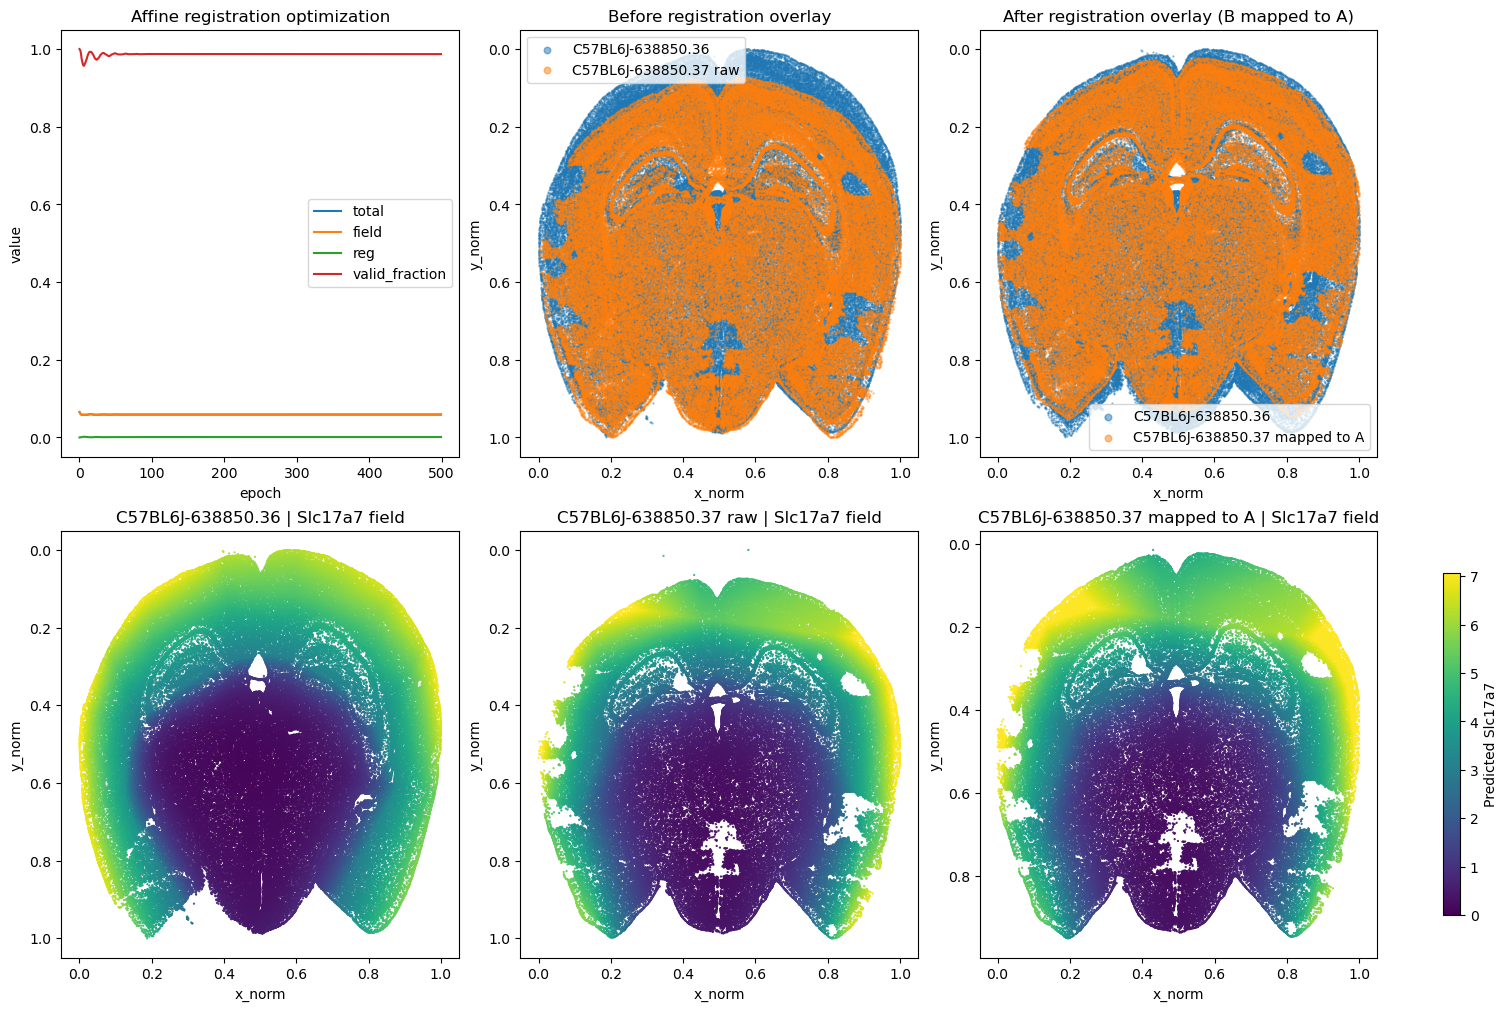

In [19]:
transform = registration_result['transform']
with torch.no_grad():
    xy_a = section_data_a['xy_norm'].to(device)
    xy_b = section_data_b['xy_norm'].to(device)
    xy_b_to_a = transform.inverse(xy_b)
    xy_b_to_a_valid_mask = in_bounds_mask(xy_b_to_a)
    xy_b_to_a_valid = xy_b_to_a[xy_b_to_a_valid_mask]

    before_loss, before_valid_fraction = registration_loss_from_models(mlp_result_a['model'], mlp_result_b['model'], registration_query_xy.to(device), Affine2D().to(device))
    after_loss, after_valid_fraction = registration_loss_from_models(mlp_result_a['model'], mlp_result_b['model'], registration_query_xy.to(device), transform)

    mlp_affine_profile_summary, mlp_affine_profile_details = mapped_profile_cosine_summary(
        mlp_result_a['model'],
        mlp_result_b['model'],
        registration_query_xy,
        transform,
    )
    mlp_data_registration_summary, mlp_data_registration_details = symmetric_crossslice_field_to_data_summary(
        mlp_result_a['model'],
        mlp_result_b['model'],
        section_data_a,
        section_data_b,
        transform.inverse,
        transform,
    )

    pred_a = torch.exp(mlp_result_a['model'](xy_a))
    pred_b_raw = torch.exp(mlp_result_b['model'](xy_b))
    pred_b_to_a_valid = torch.exp(mlp_result_b['model'](xy_b_to_a_valid)) if xy_b_to_a_valid.shape[0] > 0 else torch.empty((0, pred_a.shape[1]), device=device)

xy_a_np = xy_a.detach().cpu().numpy()
xy_b_np = xy_b.detach().cpu().numpy()
xy_b_to_a_np = xy_b_to_a.detach().cpu().numpy()
xy_b_to_a_valid_mask_np = xy_b_to_a_valid_mask.detach().cpu().numpy()
xy_b_to_a_valid_np = xy_b_to_a_valid.detach().cpu().numpy()

print('Registration summary')
print(format_for_display({
    'before_field_loss': before_loss.item(),
    'after_field_loss': after_loss.item(),
    'before_valid_fraction': before_valid_fraction.item(),
    'after_valid_fraction': after_valid_fraction.item(),
    'section_b_mapped_to_a_valid_fraction': float(xy_b_to_a_valid_mask_np.mean()),
    'mapped_profile_cosine': mlp_affine_profile_summary,
    'field_to_data': mlp_data_registration_summary,
}))

marker_gene = registration_marker_gene
if marker_gene is None:
    marker_gene = section_data_a['gene_names'][0]
marker_idx = section_data_a['gene_names'].index(marker_gene)
marker_a = pred_a[:, marker_idx].detach().cpu().numpy()
marker_b_raw = pred_b_raw[:, marker_idx].detach().cpu().numpy()
marker_b_to_a_valid = pred_b_to_a_valid[:, marker_idx].detach().cpu().numpy() if pred_b_to_a_valid.shape[0] > 0 else np.empty(0, dtype=np.float32)
marker_vmax = float(np.quantile(np.concatenate([marker_a, marker_b_raw, marker_b_to_a_valid]) if len(marker_b_to_a_valid) else np.concatenate([marker_a, marker_b_raw]), 0.99))
marker_vmax = max(marker_vmax, 1e-6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
axes[0, 0].plot(registration_result['history']['loss'], label='total')
axes[0, 0].plot(registration_result['history']['field_loss'], label='field')
axes[0, 0].plot(registration_result['history']['reg_loss'], label='reg')
axes[0, 0].plot(registration_result['history']['valid_fraction'], label='valid_fraction')
axes[0, 0].set_title('Affine registration optimization')
axes[0, 0].set_xlabel('epoch')
axes[0, 0].set_ylabel('value')
axes[0, 0].legend()

axes[0, 1].scatter(xy_a_np[:, 0], xy_a_np[:, 1], s=plot_point_size, alpha=0.5, label=f'{section_label_a}')
axes[0, 1].scatter(xy_b_np[:, 0], xy_b_np[:, 1], s=plot_point_size, alpha=0.5, label=f'{section_label_b} raw')
axes[0, 1].set_title('Before registration overlay')
axes[0, 1].set_xlabel('x_norm')
axes[0, 1].set_ylabel('y_norm')
axes[0, 1].invert_yaxis()
axes[0, 1].legend(markerscale=8)

axes[0, 2].scatter(xy_a_np[:, 0], xy_a_np[:, 1], s=plot_point_size, alpha=0.5, label=f'{section_label_a}')
if xy_b_to_a_valid_np.shape[0] > 0:
    axes[0, 2].scatter(xy_b_to_a_valid_np[:, 0], xy_b_to_a_valid_np[:, 1], s=plot_point_size, alpha=0.5, label=f'{section_label_b} mapped to A')
axes[0, 2].set_title('After registration overlay (B mapped to A)')
axes[0, 2].set_xlabel('x_norm')
axes[0, 2].set_ylabel('y_norm')
axes[0, 2].invert_yaxis()
axes[0, 2].legend(markerscale=8)

sc0 = axes[1, 0].scatter(xy_a_np[:, 0], xy_a_np[:, 1], c=marker_a, s=plot_point_size, cmap='viridis', vmin=0.0, vmax=marker_vmax)
axes[1, 0].set_title(f'{section_label_a} | {marker_gene} field')
axes[1, 0].set_xlabel('x_norm')
axes[1, 0].set_ylabel('y_norm')
axes[1, 0].invert_yaxis()

axes[1, 1].scatter(xy_b_np[:, 0], xy_b_np[:, 1], c=marker_b_raw, s=plot_point_size, cmap='viridis', vmin=0.0, vmax=marker_vmax)
axes[1, 1].set_title(f'{section_label_b} raw | {marker_gene} field')
axes[1, 1].set_xlabel('x_norm')
axes[1, 1].set_ylabel('y_norm')
axes[1, 1].invert_yaxis()

if xy_b_to_a_valid_np.shape[0] > 0:
    sc2 = axes[1, 2].scatter(xy_b_to_a_valid_np[:, 0], xy_b_to_a_valid_np[:, 1], c=marker_b_to_a_valid, s=plot_point_size, cmap='viridis', vmin=0.0, vmax=marker_vmax)
else:
    sc2 = axes[1, 2].scatter([], [], c=[], cmap='viridis', vmin=0.0, vmax=marker_vmax)
axes[1, 2].set_title(f'{section_label_b} mapped to A | {marker_gene} field')
axes[1, 2].set_xlabel('x_norm')
axes[1, 2].set_ylabel('y_norm')
axes[1, 2].invert_yaxis()

fig.colorbar(sc2, ax=axes[1, :], shrink=0.8, label=f'Predicted {marker_gene}')
export_figure_axes(fig, fallback_prefix='mlp_affine_registration')
plt.show()


## Non-Affine Registration

Start from the affine transform, then add a smooth displacement field. The non-affine objective combines field matching, splat correspondence anchors, and warp smoothness.


In [20]:
class NonAffineWarp2D(nn.Module):
    def __init__(self, base_affine: Affine2D, grid_size: int = nonaffine_grid_size):
        super().__init__()
        self.base_affine = Affine2D().to(device)
        with torch.no_grad():
            self.base_affine.linear.copy_(base_affine.linear.detach())
            self.base_affine.translation.copy_(base_affine.translation.detach())
        for param in self.base_affine.parameters():
            param.requires_grad_(False)
        self.grid_size = grid_size
        self.displacement = nn.Parameter(torch.zeros(1, 2, grid_size, grid_size, dtype=torch.float32, device=device))

    def sample_displacement(self, xy: torch.Tensor) -> torch.Tensor:
        grid = xy.view(1, -1, 1, 2) * 2.0 - 1.0
        sampled = torch.nn.functional.grid_sample(
            self.displacement,
            grid,
            mode='bilinear',
            padding_mode='border',
            align_corners=True,
        )
        return sampled.view(2, -1).T

    def forward(self, xy: torch.Tensor) -> torch.Tensor:
        affine_xy = self.base_affine(xy)
        return affine_xy + self.sample_displacement(xy)

    def inverse_approx(self, xy: torch.Tensor, steps: int = 5) -> torch.Tensor:
        estimate = self.base_affine.inverse(xy)
        for _ in range(steps):
            estimate = self.base_affine.inverse(xy - self.sample_displacement(estimate))
        return estimate


def warp_smoothness_loss(warp: NonAffineWarp2D) -> torch.Tensor:
    disp = warp.displacement
    dx = disp[:, :, 1:, :] - disp[:, :, :-1, :]
    dy = disp[:, :, :, 1:] - disp[:, :, :, :-1]
    return dx.pow(2).mean() + dy.pow(2).mean()


Non-affine anchor summary
{'candidate_matches': 502, 'reliable_anchor_matches': 360, 'mean_affine_anchor_distance': 0.01666, 'mean_affine_anchor_cosine': 0.9182}


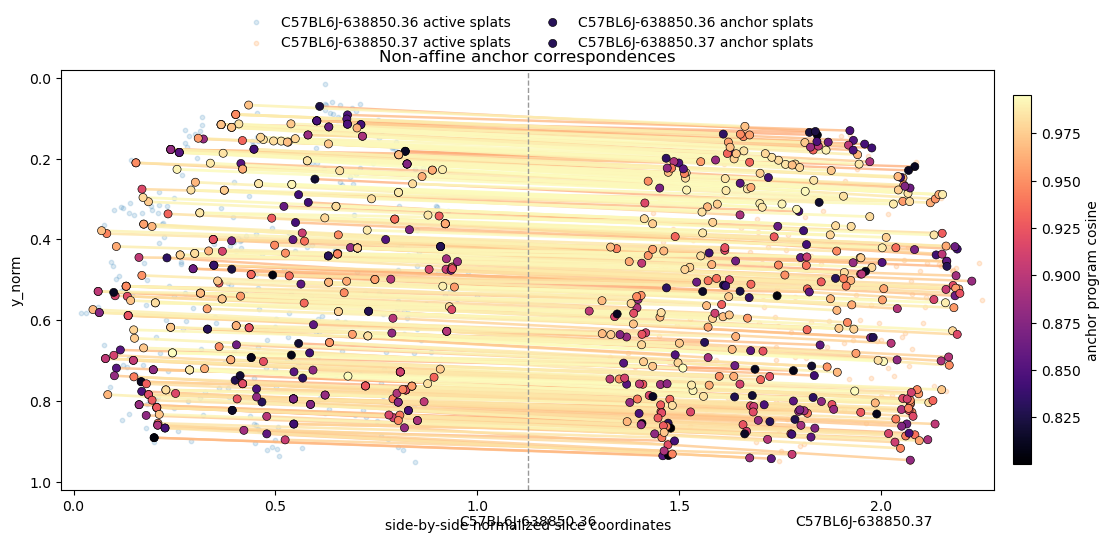

In [21]:
with torch.no_grad():
    means_a = section_a_splat_result['model'].means.detach()
    means_b = section_b_splat_result['model'].means.detach()
    active_a = (compute_splat_weights(section_a_splat_result['model'], section_data_a['xy_norm'].to(device)).mean(dim=0) > 1e-4)
    active_b = (compute_splat_weights(section_b_splat_result['model'], section_data_b['xy_norm'].to(device)).mean(dim=0) > 1e-4)

    logits_a, _ = section_a_splat_result['model'].decoder(section_a_splat_result['model'].latents)
    logits_b, _ = section_b_splat_result['model'].decoder(section_b_splat_result['model'].latents)
    profiles_a = torch.softmax(logits_a, dim=1)
    profiles_b = torch.softmax(logits_b, dim=1)
    profiles_a_norm = profiles_a / profiles_a.norm(dim=1, keepdim=True).clamp_min(1e-8)
    profiles_b_norm = profiles_b / profiles_b.norm(dim=1, keepdim=True).clamp_min(1e-8)

    means_b_to_a_affine = registration_result['transform'].inverse(means_b)
    valid_b_affine = in_bounds_mask(means_b_to_a_affine)
    match_mask_a = active_a
    match_mask_b = active_b & valid_b_affine

    means_a_match = means_a[match_mask_a]
    means_b_match = means_b[match_mask_b]
    means_b_to_a_affine_match = means_b_to_a_affine[match_mask_b]
    profiles_a_norm_match = profiles_a_norm[match_mask_a]
    profiles_b_norm_match = profiles_b_norm[match_mask_b]

    pairwise_dist = torch.cdist(means_b_to_a_affine_match, means_a_match)
    nearest_dist_affine, nearest_idx_affine = pairwise_dist.min(dim=1)
    matched_means_a = means_a_match[nearest_idx_affine]
    matched_profiles_a_norm = profiles_a_norm_match[nearest_idx_affine]
    matched_profile_cosine = (profiles_b_norm_match * matched_profiles_a_norm).sum(dim=1)

    reliable_match_mask = matched_profile_cosine >= 0.8
    anchor_means_b = means_b_match[reliable_match_mask]
    anchor_means_a = matched_means_a[reliable_match_mask]
    anchor_weights = matched_profile_cosine[reliable_match_mask].detach()

print('Non-affine anchor summary')
print(format_for_display({
    'candidate_matches': int(means_b_match.shape[0]),
    'reliable_anchor_matches': int(anchor_means_b.shape[0]),
    'mean_affine_anchor_distance': float(nearest_dist_affine[reliable_match_mask].mean().item()) if reliable_match_mask.any() else float('nan'),
    'mean_affine_anchor_cosine': float(matched_profile_cosine[reliable_match_mask].mean().item()) if reliable_match_mask.any() else float('nan'),
}))

means_a_np = means_a.detach().cpu().numpy()
means_b_np = means_b.detach().cpu().numpy()
active_a_np = active_a.detach().cpu().numpy()
active_b_np = active_b.detach().cpu().numpy()
anchor_means_a_np = anchor_means_a.detach().cpu().numpy()
anchor_means_b_np = anchor_means_b.detach().cpu().numpy()
anchor_weights_np = anchor_weights.detach().cpu().numpy() if anchor_weights.numel() else np.empty(0, dtype=np.float32)

anchor_panel_gap = 1.25
fig, ax = plt.subplots(1, 1, figsize=(11, 5.2), constrained_layout=True)
ax.scatter(means_a_np[active_a_np, 0], means_a_np[active_a_np, 1], s=10, alpha=0.16, color='tab:blue', label=f'{section_label_a} active splats')
ax.scatter(means_b_np[active_b_np, 0] + anchor_panel_gap, means_b_np[active_b_np, 1], s=10, alpha=0.16, color='tab:orange', label=f'{section_label_b} active splats')

if anchor_means_a_np.shape[0] > 0:
    anchor_order = np.argsort(anchor_weights_np)
    anchor_norm = anchor_weights_np / max(float(anchor_weights_np.max()), 1e-8)
    for anchor_idx in anchor_order:
        x_pair = [anchor_means_a_np[anchor_idx, 0], anchor_means_b_np[anchor_idx, 0] + anchor_panel_gap]
        y_pair = [anchor_means_a_np[anchor_idx, 1], anchor_means_b_np[anchor_idx, 1]]
        line_alpha = float(np.clip(0.2 + 0.65 * anchor_norm[anchor_idx], 0.2, 0.85))
        line_width = float(0.5 + 1.5 * anchor_norm[anchor_idx])
        ax.plot(x_pair, y_pair, color=plt.cm.magma(anchor_norm[anchor_idx]), alpha=line_alpha, linewidth=line_width, zorder=2)

    sc = ax.scatter(anchor_means_a_np[:, 0], anchor_means_a_np[:, 1], s=34, c=anchor_weights_np, cmap='magma', edgecolor='black', linewidth=0.45, zorder=3, label=f'{section_label_a} anchor splats')
    ax.scatter(anchor_means_b_np[:, 0] + anchor_panel_gap, anchor_means_b_np[:, 1], s=34, c=anchor_weights_np, cmap='magma', edgecolor='black', linewidth=0.45, zorder=3, label=f'{section_label_b} anchor splats')
    fig.colorbar(sc, ax=ax, shrink=0.82, pad=0.02, label='anchor program cosine')

ax.axvline(1.0 + 0.5 * (anchor_panel_gap - 1.0), color='0.6', linestyle='--', linewidth=1.0)
ax.text(0.5, -0.06, str(section_label_a), transform=ax.transAxes, ha='center', va='top')
ax.text(0.86, -0.06, str(section_label_b), transform=ax.transAxes, ha='center', va='top')
ax.set_title('Non-affine anchor correspondences')
ax.set_xlabel('side-by-side normalized slice coordinates')
ax.set_ylabel('y_norm')
ax.set_xlim(-0.03, anchor_panel_gap + 1.03)
ax.set_ylim(1.02, -0.02)
ax.set_aspect('equal')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.16), ncol=2, frameon=False)
export_figure_axes(fig, fallback_prefix='nonaffine_anchor_correspondence')
plt.show()


In [22]:
def nonaffine_registration_loss(model_a, model_b, query_xy_a: torch.Tensor, warp: NonAffineWarp2D, *, min_valid_fraction: float = nonaffine_min_valid_fraction):
    query_xy_b = warp(query_xy_a)
    valid_mask = in_bounds_mask(query_xy_b)
    valid_fraction = valid_mask.float().mean()
    if valid_mask.sum() == 0:
        return query_xy_b.new_tensor(1e3), valid_fraction
    rate_a = torch.exp(model_a(query_xy_a[valid_mask]))
    rate_b = torch.exp(model_b(query_xy_b[valid_mask]))
    field_loss = composition_cosine_loss(rate_a, rate_b)
    if valid_fraction < min_valid_fraction:
        field_loss = field_loss + (min_valid_fraction - valid_fraction) * 10.0
    return field_loss, valid_fraction


def run_nonaffine_registration(model_a, model_b, query_xy_a: torch.Tensor, *, affine_result, anchor_means_b: torch.Tensor, anchor_means_a: torch.Tensor, anchor_weights: torch.Tensor):
    warp = NonAffineWarp2D(affine_result['transform'], grid_size=nonaffine_grid_size).to(device)
    opt = torch.optim.Adam([warp.displacement], lr=nonaffine_lr)
    history = {'loss': [], 'field_loss': [], 'smoothness_loss': [], 'anchor_loss': [], 'valid_fraction': []}
    query_xy_a = query_xy_a.to(device)
    anchor_means_b = anchor_means_b.to(device)
    anchor_means_a = anchor_means_a.to(device)
    anchor_weights = anchor_weights.to(device)

    for epoch in range(nonaffine_epochs):
        field_loss, valid_fraction = nonaffine_registration_loss(model_a, model_b, query_xy_a, warp)
        smoothness_loss = warp_smoothness_loss(warp)
        if anchor_means_b.shape[0] > 0:
            mapped_anchor = warp.inverse_approx(anchor_means_b)
            anchor_dist = (mapped_anchor - anchor_means_a).pow(2).sum(dim=1).sqrt()
            anchor_loss = (anchor_dist * anchor_weights).mean()
        else:
            anchor_loss = field_loss.new_tensor(0.0)
        loss = field_loss + nonaffine_smoothness_weight * smoothness_loss + nonaffine_splat_match_weight * anchor_loss

        opt.zero_grad()
        loss.backward()
        opt.step()

        history['loss'].append(float(loss.item()))
        history['field_loss'].append(float(field_loss.item()))
        history['smoothness_loss'].append(float(smoothness_loss.item()))
        history['anchor_loss'].append(float(anchor_loss.item()))
        history['valid_fraction'].append(float(valid_fraction.item()))

        if epoch == 0 or (epoch + 1) % 50 == 0 or epoch == nonaffine_epochs - 1:
            print(f'nonaffine epoch {epoch}:', format_for_display({
                'loss': loss.item(),
                'field_loss': field_loss.item(),
                'smoothness_loss': smoothness_loss.item(),
                'anchor_loss': anchor_loss.item(),
                'valid_fraction': valid_fraction.item(),
            }))

    return {'warp': warp, 'history': history}


nonaffine_query_xy = sample_registration_queries(section_data_a['xy_norm'])
nonaffine_result = run_nonaffine_registration(
    section_a_splat_result['model'],
    section_b_splat_result['model'],
    nonaffine_query_xy,
    affine_result=registration_result,
    anchor_means_b=anchor_means_b,
    anchor_means_a=anchor_means_a,
    anchor_weights=anchor_weights,
)
print('Non-affine warp ready')


nonaffine epoch 0: {'loss': 0.151, 'field_loss': 0.1357, 'smoothness_loss': 0.0, 'anchor_loss': 0.01529, 'valid_fraction': 0.9912}
nonaffine epoch 49: {'loss': 0.1083, 'field_loss': 0.08866, 'smoothness_loss': 0.006472, 'anchor_loss': 0.01954, 'valid_fraction': 0.9988}
nonaffine epoch 99: {'loss': 0.1073, 'field_loss': 0.08841, 'smoothness_loss': 0.01115, 'anchor_loss': 0.01879, 'valid_fraction': 0.9985}
nonaffine epoch 149: {'loss': 0.1071, 'field_loss': 0.08823, 'smoothness_loss': 0.01165, 'anchor_loss': 0.01871, 'valid_fraction': 0.9985}
nonaffine epoch 199: {'loss': 0.1071, 'field_loss': 0.08832, 'smoothness_loss': 0.01221, 'anchor_loss': 0.0187, 'valid_fraction': 0.9988}
nonaffine epoch 249: {'loss': 0.1071, 'field_loss': 0.08832, 'smoothness_loss': 0.01226, 'anchor_loss': 0.01869, 'valid_fraction': 0.9988}
nonaffine epoch 299: {'loss': 0.1071, 'field_loss': 0.08832, 'smoothness_loss': 0.01228, 'anchor_loss': 0.0187, 'valid_fraction': 0.9988}
nonaffine epoch 349: {'loss': 0.1071, 

Non-affine registration summary
{'identity_field_loss': 0.2124, 'affine_field_loss': 0.1357, 'nonaffine_field_loss': 0.08832, 'identity_valid_fraction': 1.0, 'affine_valid_fraction': 0.9912, 'nonaffine_valid_fraction': 0.9988, 'section_b_nonaffine_mapped_valid_fraction': 0.9961, 'affine_mapped_profile_cosine': {'valid_fraction': 0.9912, 'mean_profile_cosine': 0.8643, 'median_profile_cosine': 0.9246, 'fraction_profile_cosine_ge_0_9': 0.5938, 'mean_topk_overlap': 0.5831, 'median_topk_overlap': 0.7}, 'nonaffine_mapped_profile_cosine': {'valid_fraction': 0.9988, 'mean_profile_cosine': 0.9117, 'median_profile_cosine': 0.9571, 'fraction_profile_cosine_ge_0_9': 0.7345, 'mean_topk_overlap': 0.6641, 'median_topk_overlap': 0.7}, 'affine_field_to_data': {'a_to_b': {'valid_fraction': 0.9888, 'mae': 0.4258, 'mean_profile_cosine': 0.6705, 'median_profile_cosine': 0.6865, 'mean_topk_overlap': 0.365, 'median_topk_overlap': 0.3}, 'b_to_a': {'valid_fraction': 0.9988, 'mae': 0.3927, 'mean_profile_cosine'

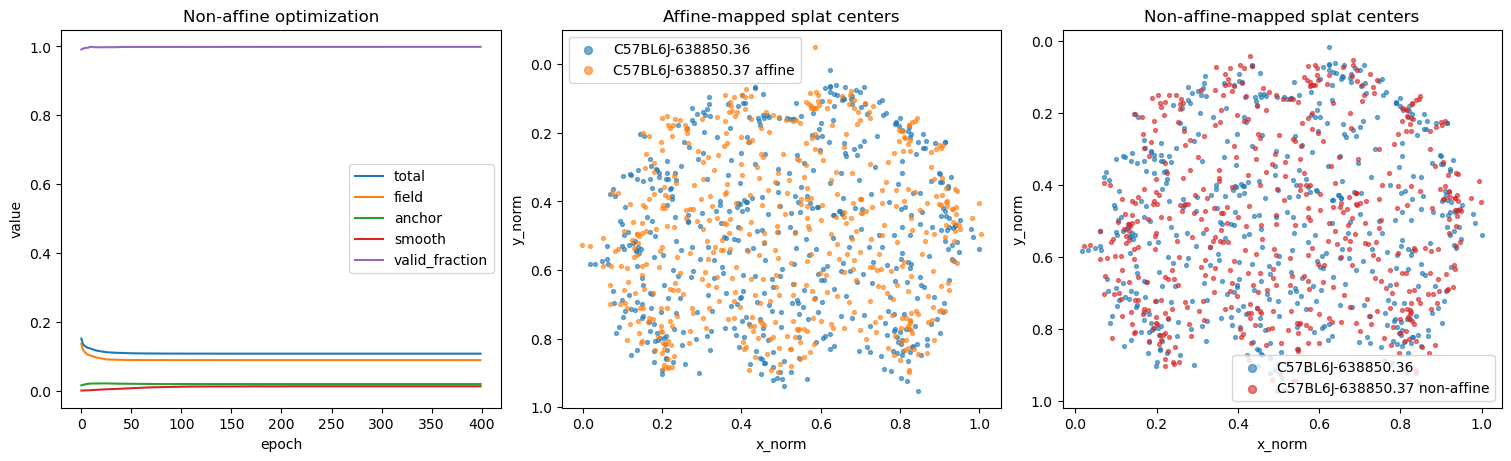

In [23]:
nonaffine_warp = nonaffine_result['warp']
with torch.no_grad():
    affine_before_loss, affine_before_valid = registration_loss_from_models(section_a_splat_result['model'], section_b_splat_result['model'], nonaffine_query_xy.to(device), Affine2D().to(device))
    affine_after_loss, affine_after_valid = registration_loss_from_models(section_a_splat_result['model'], section_b_splat_result['model'], nonaffine_query_xy.to(device), registration_result['transform'])
    nonaffine_after_loss, nonaffine_after_valid = nonaffine_registration_loss(section_a_splat_result['model'], section_b_splat_result['model'], nonaffine_query_xy.to(device), nonaffine_warp)

    splat_affine_profile_summary, splat_affine_profile_details = mapped_profile_cosine_summary(
        section_a_splat_result['model'],
        section_b_splat_result['model'],
        nonaffine_query_xy,
        registration_result['transform'],
    )
    splat_nonaffine_profile_summary, splat_nonaffine_profile_details = mapped_profile_cosine_summary(
        section_a_splat_result['model'],
        section_b_splat_result['model'],
        nonaffine_query_xy,
        nonaffine_warp,
    )
    splat_affine_data_summary, splat_affine_data_details = symmetric_crossslice_field_to_data_summary(
        section_a_splat_result['model'],
        section_b_splat_result['model'],
        section_data_a,
        section_data_b,
        registration_result['transform'].inverse,
        registration_result['transform'],
    )
    splat_nonaffine_data_summary, splat_nonaffine_data_details = symmetric_crossslice_field_to_data_summary(
        section_a_splat_result['model'],
        section_b_splat_result['model'],
        section_data_a,
        section_data_b,
        nonaffine_warp.inverse_approx,
        nonaffine_warp,
    )

    means_a = section_a_splat_result['model'].means.detach()
    means_b = section_b_splat_result['model'].means.detach()
    means_b_to_a_affine = registration_result['transform'].inverse(means_b)
    means_b_to_a_nonaffine = nonaffine_warp.inverse_approx(means_b)
    valid_nonaffine = in_bounds_mask(means_b_to_a_nonaffine)

print('Non-affine registration summary')
print(format_for_display({
    'identity_field_loss': affine_before_loss.item(),
    'affine_field_loss': affine_after_loss.item(),
    'nonaffine_field_loss': nonaffine_after_loss.item(),
    'identity_valid_fraction': affine_before_valid.item(),
    'affine_valid_fraction': affine_after_valid.item(),
    'nonaffine_valid_fraction': nonaffine_after_valid.item(),
    'section_b_nonaffine_mapped_valid_fraction': float(valid_nonaffine.float().mean().item()),
    'affine_mapped_profile_cosine': splat_affine_profile_summary,
    'nonaffine_mapped_profile_cosine': splat_nonaffine_profile_summary,
    'affine_field_to_data': splat_affine_data_summary,
    'nonaffine_field_to_data': splat_nonaffine_data_summary,
}))

means_a_np = means_a.detach().cpu().numpy()
means_b_to_a_affine_np = means_b_to_a_affine.detach().cpu().numpy()
means_b_to_a_nonaffine_np = means_b_to_a_nonaffine.detach().cpu().numpy()
valid_nonaffine_np = valid_nonaffine.detach().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
axes[0].plot(nonaffine_result['history']['loss'], label='total')
axes[0].plot(nonaffine_result['history']['field_loss'], label='field')
axes[0].plot(nonaffine_result['history']['anchor_loss'], label='anchor')
axes[0].plot(nonaffine_result['history']['smoothness_loss'], label='smooth')
axes[0].plot(nonaffine_result['history']['valid_fraction'], label='valid_fraction')
axes[0].set_title('Non-affine optimization')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('value')
axes[0].legend()

axes[1].scatter(means_a_np[:, 0], means_a_np[:, 1], s=8, alpha=0.6, color='tab:blue', label=f'{section_label_a}')
axes[1].scatter(means_b_to_a_affine_np[:, 0], means_b_to_a_affine_np[:, 1], s=8, alpha=0.6, color='tab:orange', label=f'{section_label_b} affine')
axes[1].set_title('Affine-mapped splat centers')
axes[1].set_xlabel('x_norm')
axes[1].set_ylabel('y_norm')
axes[1].invert_yaxis()
axes[1].legend(markerscale=2)

axes[2].scatter(means_a_np[:, 0], means_a_np[:, 1], s=8, alpha=0.6, color='tab:blue', label=f'{section_label_a}')
axes[2].scatter(means_b_to_a_nonaffine_np[valid_nonaffine_np, 0], means_b_to_a_nonaffine_np[valid_nonaffine_np, 1], s=8, alpha=0.6, color='tab:red', label=f'{section_label_b} non-affine')
axes[2].set_title('Non-affine-mapped splat centers')
axes[2].set_xlabel('x_norm')
axes[2].set_ylabel('y_norm')
axes[2].invert_yaxis()
axes[2].legend(markerscale=2)

export_figure_axes(fig, fallback_prefix='splat_nonaffine_registration')
plt.show()


## Cross-Slice Splat Correspondence

Use the learned affine map to place section B splats into section A coordinates, then compare nearest local components by spatial distance and decoded program similarity.


Cross-slice splat correspondence summary
{'active_splats_a': 506, 'active_splats_b': 504, 'active_valid_splats_b_mapped_to_a': 502, 'mean_match_distance': 0.01725, 'median_match_distance': 0.01571, 'mean_program_cosine': 0.8355, 'median_program_cosine': 0.888, 'mean_top10_overlap': 0.5227, 'median_top10_overlap': 0.5, 'fraction_matches_within_0.02': 0.6693, 'fraction_matches_within_0.05': 0.998}


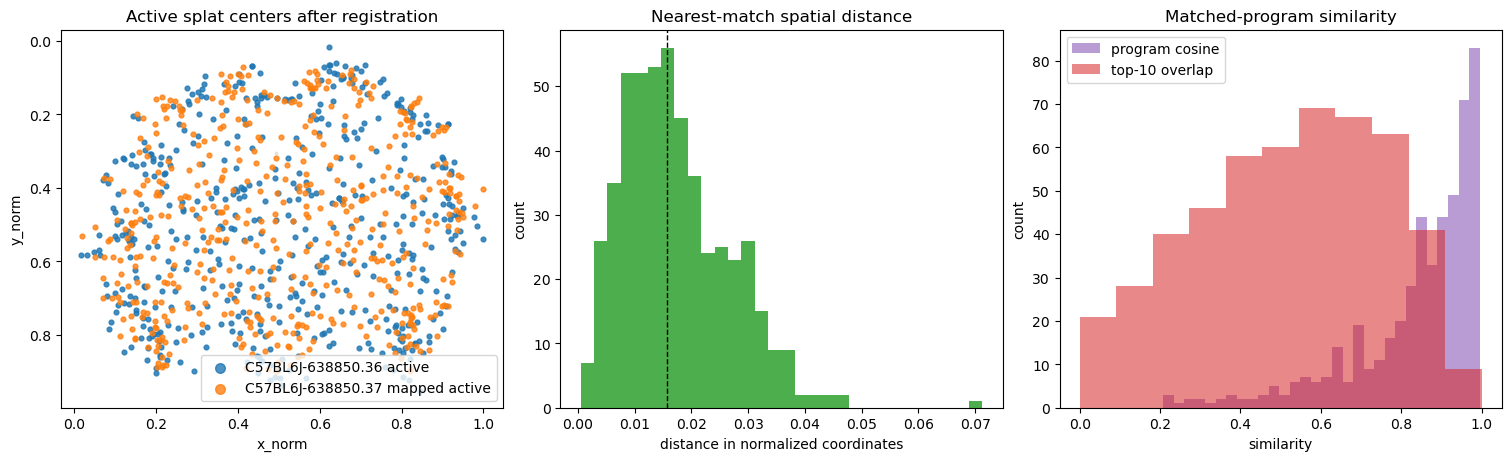

Example nearest splat matches
{'match_0': {'section_b_index': 158, 'matched_section_a_index': 246, 'distance': 0.0004883, 'program_cosine': 0.6042, 'top10_overlap': 0.1}, 'match_1': {'section_b_index': 130, 'matched_section_a_index': 103, 'distance': 0.001257, 'program_cosine': 0.9477, 'top10_overlap': 0.8}, 'match_2': {'section_b_index': 83, 'matched_section_a_index': 64, 'distance': 0.001633, 'program_cosine': 0.9848, 'top10_overlap': 0.8}, 'match_3': {'section_b_index': 240, 'matched_section_a_index': 440, 'distance': 0.002373, 'program_cosine': 0.9812, 'top10_overlap': 0.9}, 'match_4': {'section_b_index': 159, 'matched_section_a_index': 216, 'distance': 0.002478, 'program_cosine': 0.8792, 'top10_overlap': 0.4}, 'match_5': {'section_b_index': 465, 'matched_section_a_index': 493, 'distance': 0.00249, 'program_cosine': 0.7845, 'top10_overlap': 0.3}}


In [24]:
with torch.no_grad():
    splat_model_a = section_a_splat_result['model']
    splat_model_b = section_b_splat_result['model']

    mean_usage_a = compute_splat_weights(splat_model_a, section_data_a['xy_norm'].to(device)).mean(dim=0)
    mean_usage_b = compute_splat_weights(splat_model_b, section_data_b['xy_norm'].to(device)).mean(dim=0)
    active_a = mean_usage_a > 1e-4
    active_b = mean_usage_b > 1e-4

    means_a = splat_model_a.means.detach()
    means_b = splat_model_b.means.detach()
    means_b_to_a = transform.inverse(means_b)
    valid_b_to_a = in_bounds_mask(means_b_to_a)

    logits_a, _ = splat_model_a.decoder(splat_model_a.latents)
    logits_b, _ = splat_model_b.decoder(splat_model_b.latents)
    profiles_a = torch.softmax(logits_a, dim=1)
    profiles_b = torch.softmax(logits_b, dim=1)
    profiles_a_norm = profiles_a / profiles_a.norm(dim=1, keepdim=True).clamp_min(1e-8)
    profiles_b_norm = profiles_b / profiles_b.norm(dim=1, keepdim=True).clamp_min(1e-8)

    match_mask_a = active_a
    match_mask_b = active_b & valid_b_to_a

    means_a_match = means_a[match_mask_a]
    means_b_match = means_b_to_a[match_mask_b]
    profiles_a_match = profiles_a[match_mask_a]
    profiles_b_match = profiles_b[match_mask_b]
    profiles_a_norm_match = profiles_a_norm[match_mask_a]
    profiles_b_norm_match = profiles_b_norm[match_mask_b]

    if means_a_match.shape[0] == 0 or means_b_match.shape[0] == 0:
        raise RuntimeError('No active splats available for cross-slice correspondence.')

    pairwise_dist = torch.cdist(means_b_match, means_a_match)
    nearest_dist, nearest_idx = pairwise_dist.min(dim=1)
    matched_profiles_a = profiles_a_match[nearest_idx]
    matched_profiles_a_norm = profiles_a_norm_match[nearest_idx]
    profile_cosine = (profiles_b_norm_match * matched_profiles_a_norm).sum(dim=1)

    top_gene_k = min(10, profiles_a.shape[1])
    top_a = torch.topk(matched_profiles_a, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
    top_b = torch.topk(profiles_b_match, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
    top_overlap = np.array([
        len(set(top_a[i].tolist()) & set(top_b[i].tolist())) / float(top_gene_k)
        for i in range(top_a.shape[0])
    ], dtype=np.float64)

means_a_np = means_a.detach().cpu().numpy()
means_b_np = means_b.detach().cpu().numpy()
means_b_to_a_np = means_b_to_a.detach().cpu().numpy()
active_a_np = active_a.detach().cpu().numpy()
active_b_np = active_b.detach().cpu().numpy()
valid_b_to_a_np = valid_b_to_a.detach().cpu().numpy()
means_a_match_np = means_a_match.detach().cpu().numpy()
means_b_match_np = means_b_match.detach().cpu().numpy()
nearest_idx_np = nearest_idx.detach().cpu().numpy()
nearest_dist_np = nearest_dist.detach().cpu().numpy()
profile_cosine_np = profile_cosine.detach().cpu().numpy()

correspondence_summary = {
    'active_splats_a': int(active_a_np.sum()),
    'active_splats_b': int(active_b_np.sum()),
    'active_valid_splats_b_mapped_to_a': int(match_mask_b.detach().cpu().numpy().sum()),
    'mean_match_distance': float(np.mean(nearest_dist_np)),
    'median_match_distance': float(np.median(nearest_dist_np)),
    'mean_program_cosine': float(np.mean(profile_cosine_np)),
    'median_program_cosine': float(np.median(profile_cosine_np)),
    'mean_top10_overlap': float(np.mean(top_overlap)),
    'median_top10_overlap': float(np.median(top_overlap)),
    'fraction_matches_within_0.02': float(np.mean(nearest_dist_np <= 0.02)),
    'fraction_matches_within_0.05': float(np.mean(nearest_dist_np <= 0.05)),
}

print('Cross-slice splat correspondence summary')
print(format_for_display(correspondence_summary))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
axes[0].scatter(means_a_np[:, 0], means_a_np[:, 1], s=4, alpha=0.08, color='black')
axes[0].scatter(means_a_np[active_a_np, 0], means_a_np[active_a_np, 1], s=12, alpha=0.8, color='tab:blue', label=f'{section_label_a} active')
axes[0].scatter(means_b_to_a_np[valid_b_to_a_np & active_b_np, 0], means_b_to_a_np[valid_b_to_a_np & active_b_np, 1], s=12, alpha=0.8, color='tab:orange', label=f'{section_label_b} mapped active')
axes[0].set_title('Active splat centers after registration')
axes[0].set_xlabel('x_norm')
axes[0].set_ylabel('y_norm')
axes[0].invert_yaxis()
axes[0].legend(markerscale=2)

axes[1].hist(nearest_dist_np, bins=30, alpha=0.85, color='tab:green')
axes[1].axvline(np.median(nearest_dist_np), linestyle='--', color='black', linewidth=1.0)
axes[1].set_title('Nearest-match spatial distance')
axes[1].set_xlabel('distance in normalized coordinates')
axes[1].set_ylabel('count')

axes[2].hist(profile_cosine_np, bins=30, alpha=0.65, color='tab:purple', label='program cosine')
axes[2].hist(top_overlap, bins=np.linspace(0.0, 1.0, top_gene_k + 2), alpha=0.55, color='tab:red', label='top-10 overlap')
axes[2].set_title('Matched-program similarity')
axes[2].set_xlabel('similarity')
axes[2].set_ylabel('count')
axes[2].legend()

export_figure_axes(fig, fallback_prefix='splat_correspondence')
plt.show()

num_examples = min(6, means_b_match_np.shape[0])
example_order = np.argsort(nearest_dist_np)[:num_examples]
example_summary = {
    f'match_{i}': {
        'section_b_index': int(np.flatnonzero(match_mask_b.detach().cpu().numpy())[example_order[i]]),
        'matched_section_a_index': int(np.flatnonzero(match_mask_a.detach().cpu().numpy())[nearest_idx_np[example_order[i]]]),
        'distance': float(nearest_dist_np[example_order[i]]),
        'program_cosine': float(profile_cosine_np[example_order[i]]),
        'top10_overlap': float(top_overlap[example_order[i]]),
    }
    for i in range(num_examples)
}
print('Example nearest splat matches')
print(format_for_display(example_summary))


The correspondence summary should be interpreted along three axes:

- **Spatial agreement:** low nearest-match distance means the registered splat centers from section B land close to active splats in section A.
- **Program agreement:** high decoded-profile cosine means those nearby components also represent similar biology, not just similar geometry.
- **Top-gene overlap:** overlap in the strongest decoded genes gives a more interpretable discrete check on whether matched splats preserve the same local program identity.

Taken together, strong correspondence means the splat field is doing more than supporting a smooth affine alignment. It is also exposing localized cross-slice components that can be compared directly after registration.


In [25]:
def summarize_splat_correspondence(model_a, model_b, warp_inverse_fn, section_xy_a: torch.Tensor, section_xy_b: torch.Tensor):
    with torch.no_grad():
        mean_usage_a = compute_splat_weights(model_a, section_xy_a.to(device)).mean(dim=0)
        mean_usage_b = compute_splat_weights(model_b, section_xy_b.to(device)).mean(dim=0)
        active_a = mean_usage_a > 1e-4
        active_b = mean_usage_b > 1e-4

        means_a = model_a.means.detach()
        means_b = model_b.means.detach()
        means_b_to_a = warp_inverse_fn(means_b)
        valid_b_to_a = in_bounds_mask(means_b_to_a)

        logits_a, _ = model_a.decoder(model_a.latents)
        logits_b, _ = model_b.decoder(model_b.latents)
        profiles_a = torch.softmax(logits_a, dim=1)
        profiles_b = torch.softmax(logits_b, dim=1)
        profiles_a_norm = profiles_a / profiles_a.norm(dim=1, keepdim=True).clamp_min(1e-8)
        profiles_b_norm = profiles_b / profiles_b.norm(dim=1, keepdim=True).clamp_min(1e-8)

        match_mask_a = active_a
        match_mask_b = active_b & valid_b_to_a
        means_a_match = means_a[match_mask_a]
        means_b_match = means_b_to_a[match_mask_b]
        profiles_a_match = profiles_a[match_mask_a]
        profiles_b_match = profiles_b[match_mask_b]
        profiles_a_norm_match = profiles_a_norm[match_mask_a]
        profiles_b_norm_match = profiles_b_norm[match_mask_b]

        if means_a_match.shape[0] == 0 or means_b_match.shape[0] == 0:
            raise RuntimeError('No active splats available for correspondence summary.')

        pairwise_dist = torch.cdist(means_b_match, means_a_match)
        nearest_dist, nearest_idx = pairwise_dist.min(dim=1)
        matched_profiles_a = profiles_a_match[nearest_idx]
        matched_profiles_a_norm = profiles_a_norm_match[nearest_idx]
        profile_cosine = (profiles_b_norm_match * matched_profiles_a_norm).sum(dim=1)

        top_gene_k = min(10, profiles_a.shape[1])
        top_a = torch.topk(matched_profiles_a, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        top_b = torch.topk(profiles_b_match, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        top_overlap = np.array([
            len(set(top_a[i].tolist()) & set(top_b[i].tolist())) / float(top_gene_k)
            for i in range(top_a.shape[0])
        ], dtype=np.float64)

    nearest_dist_np = nearest_dist.detach().cpu().numpy()
    profile_cosine_np = profile_cosine.detach().cpu().numpy()
    summary = {
        'active_splats_a': int(active_a.detach().cpu().numpy().sum()),
        'active_splats_b': int(active_b.detach().cpu().numpy().sum()),
        'active_valid_splats_b_mapped_to_a': int(match_mask_b.detach().cpu().numpy().sum()),
        'mean_match_distance': float(np.mean(nearest_dist_np)),
        'median_match_distance': float(np.median(nearest_dist_np)),
        'mean_program_cosine': float(np.mean(profile_cosine_np)),
        'median_program_cosine': float(np.median(profile_cosine_np)),
        'mean_top10_overlap': float(np.mean(top_overlap)),
        'median_top10_overlap': float(np.median(top_overlap)),
        'fraction_matches_within_0.02': float(np.mean(nearest_dist_np <= 0.02)),
        'fraction_matches_within_0.05': float(np.mean(nearest_dist_np <= 0.05)),
    }
    details = {
        'nearest_dist': nearest_dist_np,
        'profile_cosine': profile_cosine_np,
        'top_overlap': top_overlap,
    }
    return summary, details


Affine vs non-affine correspondence comparison
{'affine': {'active_splats_a': 506, 'active_splats_b': 504, 'active_valid_splats_b_mapped_to_a': 502, 'mean_match_distance': 0.01725, 'median_match_distance': 0.01571, 'mean_program_cosine': 0.8355, 'median_program_cosine': 0.888, 'mean_top10_overlap': 0.5227, 'median_top10_overlap': 0.5, 'fraction_matches_within_0.02': 0.6693, 'fraction_matches_within_0.05': 0.998}, 'nonaffine': {'active_splats_a': 506, 'active_splats_b': 504, 'active_valid_splats_b_mapped_to_a': 504, 'mean_match_distance': 0.01712, 'median_match_distance': 0.01624, 'mean_program_cosine': 0.8505, 'median_program_cosine': 0.9065, 'mean_top10_overlap': 0.5444, 'median_top10_overlap': 0.6, 'fraction_matches_within_0.02': 0.6488, 'fraction_matches_within_0.05': 0.996}, 'delta_nonaffine_minus_affine': {'mean_match_distance': -0.0001327, 'median_match_distance': 0.0005367, 'mean_program_cosine': 0.01495, 'median_program_cosine': 0.01845, 'mean_top10_overlap': 0.02174, 'median_t

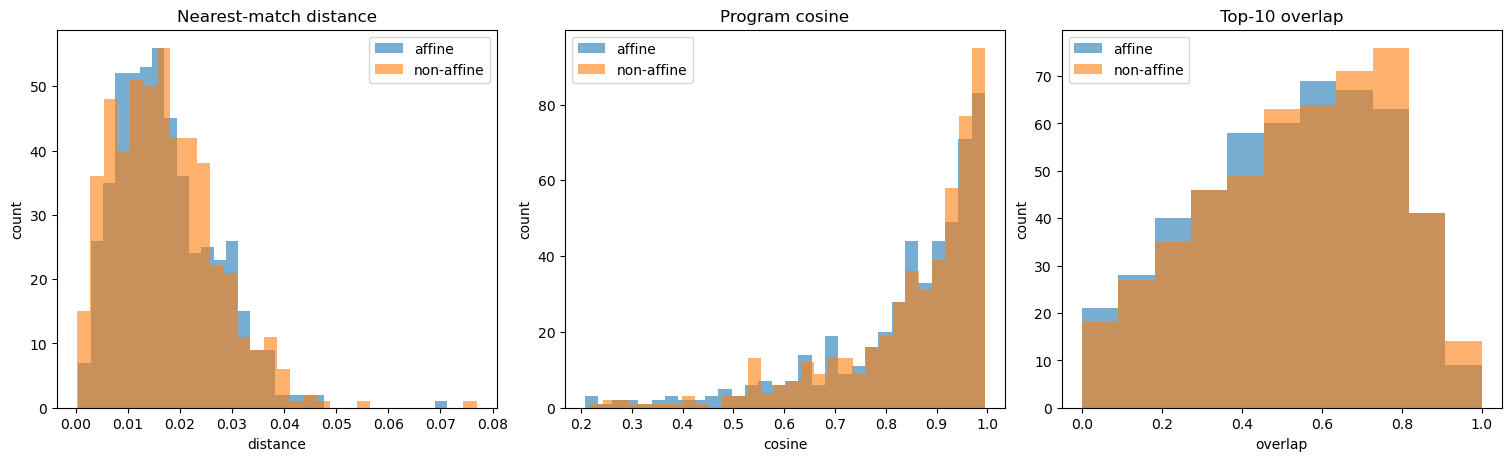

In [26]:
affine_corr_summary, affine_corr_details = summarize_splat_correspondence(
    section_a_splat_result['model'],
    section_b_splat_result['model'],
    registration_result['transform'].inverse,
    section_data_a['xy_norm'],
    section_data_b['xy_norm'],
)
nonaffine_corr_summary, nonaffine_corr_details = summarize_splat_correspondence(
    section_a_splat_result['model'],
    section_b_splat_result['model'],
    nonaffine_result['warp'].inverse_approx,
    section_data_a['xy_norm'],
    section_data_b['xy_norm'],
)

comparison_summary = {
    'affine': affine_corr_summary,
    'nonaffine': nonaffine_corr_summary,
    'delta_nonaffine_minus_affine': {
        'mean_match_distance': nonaffine_corr_summary['mean_match_distance'] - affine_corr_summary['mean_match_distance'],
        'median_match_distance': nonaffine_corr_summary['median_match_distance'] - affine_corr_summary['median_match_distance'],
        'mean_program_cosine': nonaffine_corr_summary['mean_program_cosine'] - affine_corr_summary['mean_program_cosine'],
        'median_program_cosine': nonaffine_corr_summary['median_program_cosine'] - affine_corr_summary['median_program_cosine'],
        'mean_top10_overlap': nonaffine_corr_summary['mean_top10_overlap'] - affine_corr_summary['mean_top10_overlap'],
        'median_top10_overlap': nonaffine_corr_summary['median_top10_overlap'] - affine_corr_summary['median_top10_overlap'],
        'fraction_matches_within_0.02': nonaffine_corr_summary['fraction_matches_within_0.02'] - affine_corr_summary['fraction_matches_within_0.02'],
        'fraction_matches_within_0.05': nonaffine_corr_summary['fraction_matches_within_0.05'] - affine_corr_summary['fraction_matches_within_0.05'],
    },
}
print('Affine vs non-affine correspondence comparison')
print(format_for_display(comparison_summary))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
axes[0].hist(affine_corr_details['nearest_dist'], bins=30, alpha=0.6, label='affine', color='tab:blue')
axes[0].hist(nonaffine_corr_details['nearest_dist'], bins=30, alpha=0.6, label='non-affine', color='tab:orange')
axes[0].set_title('Nearest-match distance')
axes[0].set_xlabel('distance')
axes[0].set_ylabel('count')
axes[0].legend()

axes[1].hist(affine_corr_details['profile_cosine'], bins=30, alpha=0.6, label='affine', color='tab:blue')
axes[1].hist(nonaffine_corr_details['profile_cosine'], bins=30, alpha=0.6, label='non-affine', color='tab:orange')
axes[1].set_title('Program cosine')
axes[1].set_xlabel('cosine')
axes[1].set_ylabel('count')
axes[1].legend()

bins = np.linspace(0.0, 1.0, 12)
axes[2].hist(affine_corr_details['top_overlap'], bins=bins, alpha=0.6, label='affine', color='tab:blue')
axes[2].hist(nonaffine_corr_details['top_overlap'], bins=bins, alpha=0.6, label='non-affine', color='tab:orange')
axes[2].set_title('Top-10 overlap')
axes[2].set_xlabel('overlap')
axes[2].set_ylabel('count')
axes[2].legend()
export_figure_axes(fig, fallback_prefix='affine_vs_nonaffine_correspondence')
plt.show()


Registration method comparison summary
{'mlp_affine': {'field_loss': 0.05899, 'valid_fraction': 0.9871, 'mean_mapped_profile_cosine': 0.941, 'mean_mapped_topk_overlap': 0.7954, 'field_to_data_mean_mae': 0.3959, 'field_to_data_mean_cosine': 0.5463, 'field_to_data_mean_topk_overlap': 0.296}, 'splat_affine': {'field_loss': 0.1357, 'valid_fraction': 0.9912, 'mean_match_distance': 0.01725, 'mean_program_cosine': 0.8355, 'mean_mapped_profile_cosine': 0.8643, 'mean_mapped_topk_overlap': 0.5831, 'field_to_data_mean_mae': 0.4092, 'field_to_data_mean_cosine': 0.669, 'field_to_data_mean_topk_overlap': 0.3695}, 'splat_nonaffine': {'field_loss': 0.08832, 'valid_fraction': 0.9988, 'mean_match_distance': 0.01712, 'mean_program_cosine': 0.8505, 'mean_mapped_profile_cosine': 0.9117, 'mean_mapped_topk_overlap': 0.6641, 'field_to_data_mean_mae': 0.3928, 'field_to_data_mean_cosine': 0.6958, 'field_to_data_mean_topk_overlap': 0.4043}}


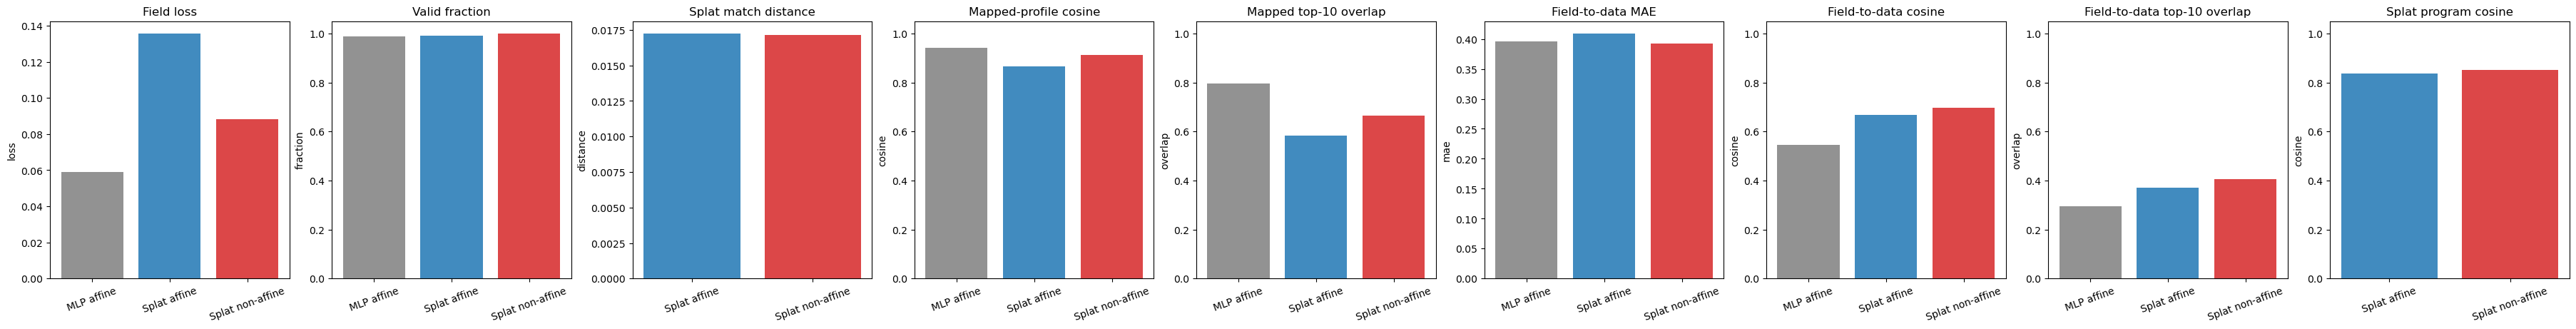

In [27]:
mlp_affine_plot_summary = {
    'field_loss': float(after_loss.item()),
    'valid_fraction': float(after_valid_fraction.item()),
    'mean_mapped_profile_cosine': float(mlp_affine_profile_summary['mean_profile_cosine']),
    'mean_mapped_topk_overlap': float(mlp_affine_profile_summary['mean_topk_overlap']),
    'field_to_data_mean_mae': float(mlp_data_registration_summary['symmetric_mean']['mean_mae']),
    'field_to_data_mean_cosine': float(mlp_data_registration_summary['symmetric_mean']['mean_profile_cosine']),
    'field_to_data_mean_topk_overlap': float(mlp_data_registration_summary['symmetric_mean']['mean_topk_overlap']),
}
splat_affine_plot_summary = {
    'field_loss': float(affine_after_loss.item()),
    'valid_fraction': float(affine_after_valid.item()),
    'mean_match_distance': float(affine_corr_summary['mean_match_distance']),
    'mean_program_cosine': float(affine_corr_summary['mean_program_cosine']),
    'mean_mapped_profile_cosine': float(splat_affine_profile_summary['mean_profile_cosine']),
    'mean_mapped_topk_overlap': float(splat_affine_profile_summary['mean_topk_overlap']),
    'field_to_data_mean_mae': float(splat_affine_data_summary['symmetric_mean']['mean_mae']),
    'field_to_data_mean_cosine': float(splat_affine_data_summary['symmetric_mean']['mean_profile_cosine']),
    'field_to_data_mean_topk_overlap': float(splat_affine_data_summary['symmetric_mean']['mean_topk_overlap']),
}
splat_nonaffine_plot_summary = {
    'field_loss': float(nonaffine_after_loss.item()),
    'valid_fraction': float(nonaffine_after_valid.item()),
    'mean_match_distance': float(nonaffine_corr_summary['mean_match_distance']),
    'mean_program_cosine': float(nonaffine_corr_summary['mean_program_cosine']),
    'mean_mapped_profile_cosine': float(splat_nonaffine_profile_summary['mean_profile_cosine']),
    'mean_mapped_topk_overlap': float(splat_nonaffine_profile_summary['mean_topk_overlap']),
    'field_to_data_mean_mae': float(splat_nonaffine_data_summary['symmetric_mean']['mean_mae']),
    'field_to_data_mean_cosine': float(splat_nonaffine_data_summary['symmetric_mean']['mean_profile_cosine']),
    'field_to_data_mean_topk_overlap': float(splat_nonaffine_data_summary['symmetric_mean']['mean_topk_overlap']),
}

print('Registration method comparison summary')
print(format_for_display({
    'mlp_affine': mlp_affine_plot_summary,
    'splat_affine': splat_affine_plot_summary,
    'splat_nonaffine': splat_nonaffine_plot_summary,
}))

labels = ['MLP affine', 'Splat affine', 'Splat non-affine']
field_losses = [
    mlp_affine_plot_summary['field_loss'],
    splat_affine_plot_summary['field_loss'],
    splat_nonaffine_plot_summary['field_loss'],
]
valid_fractions = [
    mlp_affine_plot_summary['valid_fraction'],
    splat_affine_plot_summary['valid_fraction'],
    splat_nonaffine_plot_summary['valid_fraction'],
]
mean_match_distances = [
    np.nan,
    splat_affine_plot_summary['mean_match_distance'],
    splat_nonaffine_plot_summary['mean_match_distance'],
]
mean_program_cosines = [
    np.nan,
    splat_affine_plot_summary['mean_program_cosine'],
    splat_nonaffine_plot_summary['mean_program_cosine'],
]
mapped_profile_cosines = [
    mlp_affine_plot_summary['mean_mapped_profile_cosine'],
    splat_affine_plot_summary['mean_mapped_profile_cosine'],
    splat_nonaffine_plot_summary['mean_mapped_profile_cosine'],
]
mapped_topk_overlaps = [
    mlp_affine_plot_summary['mean_mapped_topk_overlap'],
    splat_affine_plot_summary['mean_mapped_topk_overlap'],
    splat_nonaffine_plot_summary['mean_mapped_topk_overlap'],
]
field_to_data_mae = [
    mlp_affine_plot_summary['field_to_data_mean_mae'],
    splat_affine_plot_summary['field_to_data_mean_mae'],
    splat_nonaffine_plot_summary['field_to_data_mean_mae'],
]
field_to_data_cosine = [
    mlp_affine_plot_summary['field_to_data_mean_cosine'],
    splat_affine_plot_summary['field_to_data_mean_cosine'],
    splat_nonaffine_plot_summary['field_to_data_mean_cosine'],
]
field_to_data_topk = [
    mlp_affine_plot_summary['field_to_data_mean_topk_overlap'],
    splat_affine_plot_summary['field_to_data_mean_topk_overlap'],
    splat_nonaffine_plot_summary['field_to_data_mean_topk_overlap'],
]
colors = ['tab:gray', 'tab:blue', 'tab:red']

fig, axes = plt.subplots(1, 9, figsize=(36, 4.5), constrained_layout=True)
axes[0].bar(labels, field_losses, color=colors, alpha=0.85)
axes[0].set_title('Field loss')
axes[0].set_ylabel('loss')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(labels, valid_fractions, color=colors, alpha=0.85)
axes[1].set_title('Valid fraction')
axes[1].set_ylabel('fraction')
axes[1].set_ylim(0.0, 1.05)
axes[1].tick_params(axis='x', rotation=20)

axes[2].bar(labels[1:], mean_match_distances[1:], color=colors[1:], alpha=0.85)
axes[2].set_title('Splat match distance')
axes[2].set_ylabel('distance')
axes[2].tick_params(axis='x', rotation=20)

axes[3].bar(labels, mapped_profile_cosines, color=colors, alpha=0.85)
axes[3].set_title('Mapped-profile cosine')
axes[3].set_ylabel('cosine')
axes[3].set_ylim(0.0, 1.05)
axes[3].tick_params(axis='x', rotation=20)

axes[4].bar(labels, mapped_topk_overlaps, color=colors, alpha=0.85)
axes[4].set_title('Mapped top-10 overlap')
axes[4].set_ylabel('overlap')
axes[4].set_ylim(0.0, 1.05)
axes[4].tick_params(axis='x', rotation=20)

axes[5].bar(labels, field_to_data_mae, color=colors, alpha=0.85)
axes[5].set_title('Field-to-data MAE')
axes[5].set_ylabel('mae')
axes[5].tick_params(axis='x', rotation=20)

axes[6].bar(labels, field_to_data_cosine, color=colors, alpha=0.85)
axes[6].set_title('Field-to-data cosine')
axes[6].set_ylabel('cosine')
axes[6].set_ylim(0.0, 1.05)
axes[6].tick_params(axis='x', rotation=20)

axes[7].bar(labels, field_to_data_topk, color=colors, alpha=0.85)
axes[7].set_title('Field-to-data top-10 overlap')
axes[7].set_ylabel('overlap')
axes[7].set_ylim(0.0, 1.05)
axes[7].tick_params(axis='x', rotation=20)

axes[8].bar(labels[1:], mean_program_cosines[1:], color=colors[1:], alpha=0.85)
axes[8].set_title('Splat program cosine')
axes[8].set_ylabel('cosine')
axes[8].set_ylim(0.0, 1.05)
axes[8].tick_params(axis='x', rotation=20)

export_figure_axes(fig, fallback_prefix='registration_method_comparison')
plt.show()
